# 0. Reproducing Raman et al. (2026): a guided, independent walkthrough

**Question:** how do five classifiers compare on coronary heart disease labels in two small public datasets, and does their ranking survive a different train/test split?

Raman et al., *Machine Learning for Coronary Heart Disease Prediction: Comparative Analysis of Framingham and Cleveland Subset of the UCI Dataset with SHAP-Based Interpretability*, **Epidemiologia 7(3):75**, [doi:10.3390/epidemiologia7030075](https://doi.org/10.3390/epidemiologia7030075), compare LR, RF, KNN, XGBoost and a feedforward NN. We follow the [current PMC methods and leakage-controlled Tables 2–3](https://pmc.ncbi.nlm.nih.gov/articles/PMC13298444/), not the preliminary optimistic results mentioned in the article. Framingham predicts a **10-year CHD outcome**; Cleveland classifies **existing disease**, so their AUROCs are not directly comparable.

This notebook contains all its analysis code. Install `requirements.txt` beside it with Python 3.12, then run all cells. Downloads are cached in `notebooks/data/`; only public teaching data are used. No clinical advice, causal conclusions, or external validation are implied. Each section explains the paper's method, shows the calculation, and interprets the result.

In [1]:
import os
import random
import time
import warnings
from pathlib import Path

START = time.perf_counter()
SEED = 42
N_SPLITS = 50
assert isinstance(N_SPLITS, int) and N_SPLITS >= 2
for name in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS'):
    os.environ[name] = '1'
random.seed(SEED)
warnings.filterwarnings('ignore', message='IProgress not found.*', category=Warning)


In [2]:
import hashlib
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from IPython.display import display, Markdown
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.calibration import calibration_curve
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, roc_auc_score, brier_score_loss,
    RocCurveDisplay, ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
import shap

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
MODELS = ['LR', 'RF', 'KNN', 'XGB', 'NN']
COLORS = dict(zip(MODELS, sns.color_palette('colorblind', 5)))
sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 100})


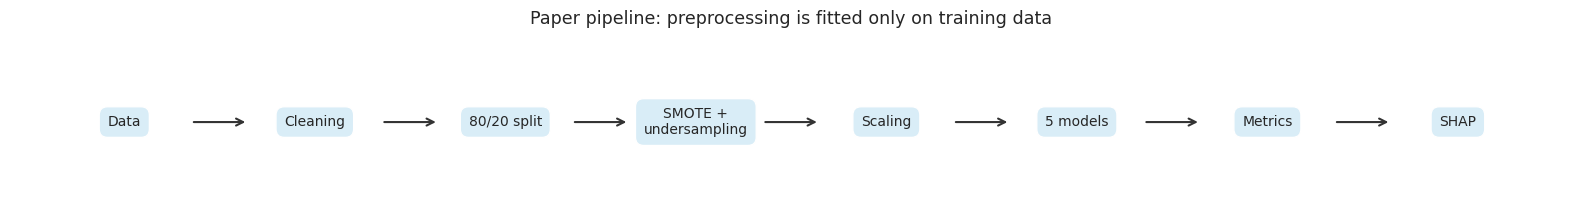

In [3]:
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')

stages = ['Data', 'Cleaning', '80/20 split', 'SMOTE +\nundersampling',
          'Scaling', '5 models', 'Metrics', 'SHAP']
fig, ax = plt.subplots(figsize=(16, 2.4))
for i, stage in enumerate(stages):
    ax.text(i, 0, stage, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=0.6', facecolor='#d9edf7'))
    if i < len(stages) - 1:
        ax.annotate('', xy=(i + 0.65, 0), xytext=(i + 0.35, 0),
                    arrowprops=dict(arrowstyle='->', color='#333333', linewidth=1.5))
ax.set(xlim=(-0.6, 7.6), ylim=(-0.8, 0.8),
       title='Paper pipeline: preprocessing is fitted only on training data')
ax.axis('off')
plt.tight_layout()
plt.show()


The split is the key boundary: neither the final test set nor a validation fold may influence fitted preprocessing. SHAP is a post-fit explanation of XGBoost, not an additional predictive model.

## 1. Load and fingerprint the public datasets

Paper §2.1 describes 303 Cleveland records and a Framingham teaching extract. We use the [UCI Cleveland file](https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data) (CC BY 4.0) and the [STA210 teaching mirror](https://github.com/sta210-sp20/datasets/blob/master/framingham.csv) specified in the repository's original data issue. The Framingham mirror's redistribution terms are not established here; raw files are cached locally, not committed. These byte-level fingerprints make source changes fail loudly rather than silently changing the experiment.

In [4]:
HERE = Path.cwd()
NOTEBOOK_DIR = HERE if HERE.name == 'notebooks' else HERE / 'notebooks'
DATA_DIR = NOTEBOOK_DIR / 'data'
DATA_DIR.mkdir(parents=True, exist_ok=True)
SOURCES = {
    'processed.cleveland.data': (
        'https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data',
        'a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8'),
    'framingham.csv': (
        'https://raw.githubusercontent.com/sta210-sp20/datasets/master/framingham.csv',
        '2c0e57dc0361b420becf1facec0a054af06c420eae0ae2faf0fdc8591fadb018'),
}
for filename, (url, expected_hash) in SOURCES.items():
    destination = DATA_DIR / filename
    if not destination.exists():
        with urlopen(url, timeout=60) as response:
            content = response.read()
        assert hashlib.sha256(content).hexdigest() == expected_hash, filename
        destination.write_bytes(content)
    digest = hashlib.sha256(destination.read_bytes()).hexdigest()
    assert digest == expected_hash, f'Unexpected data fingerprint: {filename}'
    print(f'{filename}: SHA-256 {digest}')

CLEVELAND_COLUMNS = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs',
    'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']
raw = {
    'Cleveland': pd.read_csv(DATA_DIR / 'processed.cleveland.data',
                             names=CLEVELAND_COLUMNS, na_values='?'),
    'Framingham': pd.read_csv(DATA_DIR / 'framingham.csv'),
}
for dataset, frame in raw.items():
    display(Markdown(f'### {dataset}: {frame.shape[0]} rows × {frame.shape[1]} columns'))
    display(frame.head())
    display(frame.dtypes.astype(str).rename('dtype').to_frame().T)


processed.cleveland.data: SHA-256 a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8
framingham.csv: SHA-256 2c0e57dc0361b420becf1facec0a054af06c420eae0ae2faf0fdc8591fadb018


### Cleveland: 303 rows × 14 columns

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64


### Framingham: 4240 rows × 16 columns

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
dtype,int64,int64,float64,int64,float64,float64,int64,int64,int64,float64,float64,float64,float64,float64,float64,int64


### Data dictionaries

The Cleveland codes are described in the [UCI heart-disease documentation](https://archive.ics.uci.edu/dataset/45/heart+disease); Framingham names follow the teaching extract. A numerical dtype does **not** make a coded category continuous. We identify those categories explicitly for EDA; the modelling assumption is to retain their numeric codes rather than one-hot encode them.

In [5]:
cleveland_dictionary = [
    ('age', 'Age (years)', 'continuous'),
    ('sex', 'Recorded sex: 1 male, 0 female', 'binary'),
    ('cp', 'Chest pain: 1 typical, 2 atypical, 3 non-anginal, 4 asymptomatic', 'categorical'),
    ('trestbps', 'Resting blood pressure (mmHg)', 'continuous'),
    ('chol', 'Serum cholesterol (mg/dL)', 'continuous'),
    ('fbs', 'Fasting blood sugar >120 mg/dL', 'binary'),
    ('restecg', 'Resting ECG: 0 normal, 1 ST-T abnormality, 2 LV hypertrophy', 'categorical'),
    ('thalach', 'Maximum achieved heart rate (beats/min)', 'continuous'),
    ('exang', 'Exercise-induced angina', 'binary'),
    ('oldpeak', 'Exercise-induced ST depression', 'continuous'),
    ('slope', 'Peak ST slope: 1 up, 2 flat, 3 down', 'categorical'),
    ('ca', 'Major vessels coloured by fluoroscopy (0–3)', 'ordinal'),
    ('thal', 'Thallium test: 3 normal, 6 fixed defect, 7 reversible defect', 'categorical'),
    ('num', 'Diagnosis: 0 absent, 1–4 present; target becomes num > 0', 'outcome'),
]
framingham_dictionary = [
    ('male', 'Recorded sex: 1 male, 0 female', 'binary'),
    ('age', 'Age (years)', 'continuous'),
    ('education', 'Education level, coded 1–4', 'ordinal'),
    ('currentSmoker', 'Current smoking status', 'binary'),
    ('cigsPerDay', 'Cigarettes smoked per day', 'continuous/count'),
    ('BPMeds', 'Taking blood-pressure medication', 'binary'),
    ('prevalentStroke', 'Previous stroke', 'binary'),
    ('prevalentHyp', 'Prevalent hypertension', 'binary'),
    ('diabetes', 'Diabetes indicator', 'binary'),
    ('totChol', 'Total cholesterol (mg/dL)', 'continuous'),
    ('sysBP', 'Systolic blood pressure (mmHg)', 'continuous'),
    ('diaBP', 'Diastolic blood pressure (mmHg)', 'continuous'),
    ('BMI', 'Body mass index (kg/m²)', 'continuous'),
    ('heartRate', 'Heart rate (beats/min)', 'continuous'),
    ('glucose', 'Glucose (mg/dL)', 'continuous'),
    ('TenYearCHD', 'CHD event within ten years', 'outcome'),
]
for dataset, entries in [('Cleveland', cleveland_dictionary),
                         ('Framingham', framingham_dictionary)]:
    display(Markdown(f'**{dataset} dictionary**'))
    display(pd.DataFrame(entries, columns=['feature', 'meaning', 'type']))


**Cleveland dictionary**

,feature,meaning,type
0,age,Age (years),continuous
1,sex,"Recorded sex: 1 male, 0 female",binary
2,cp,"Chest pain: 1 typical, 2 atypical, 3 non-angin...",categorical
3,trestbps,Resting blood pressure (mmHg),continuous
4,chol,Serum cholesterol (mg/dL),continuous
5,fbs,Fasting blood sugar >120 mg/dL,binary
6,restecg,"Resting ECG: 0 normal, 1 ST-T abnormality, 2 L...",categorical
7,thalach,Maximum achieved heart rate (beats/min),continuous
8,exang,Exercise-induced angina,binary
9,oldpeak,Exercise-induced ST depression,continuous


**Framingham dictionary**

,feature,meaning,type
0,male,"Recorded sex: 1 male, 0 female",binary
1,age,Age (years),continuous
2,education,"Education level, coded 1–4",ordinal
3,currentSmoker,Current smoking status,binary
4,cigsPerDay,Cigarettes smoked per day,continuous/count
5,BPMeds,Taking blood-pressure medication,binary
6,prevalentStroke,Previous stroke,binary
7,prevalentHyp,Prevalent hypertension,binary
8,diabetes,Diabetes indicator,binary
9,totChol,Total cholesterol (mg/dL),continuous


The previews establish the feature schemas and show why missing data need attention before fitting any estimator. Cleveland's diagnosis is not yet a binary label. Framingham includes both a smoking-status flag and daily cigarette count, which must not be conflated when comparing SHAP rankings.

## 2. Exploratory analysis before cleaning

We first inspect missingness, class balance, and feature distributions. These descriptive views use the raw records, with missing values omitted only within each plotted feature; they do not choose hyperparameters or change the pre-specified analysis. Full-data EDA can otherwise tempt test-informed model choices, which we avoid here.

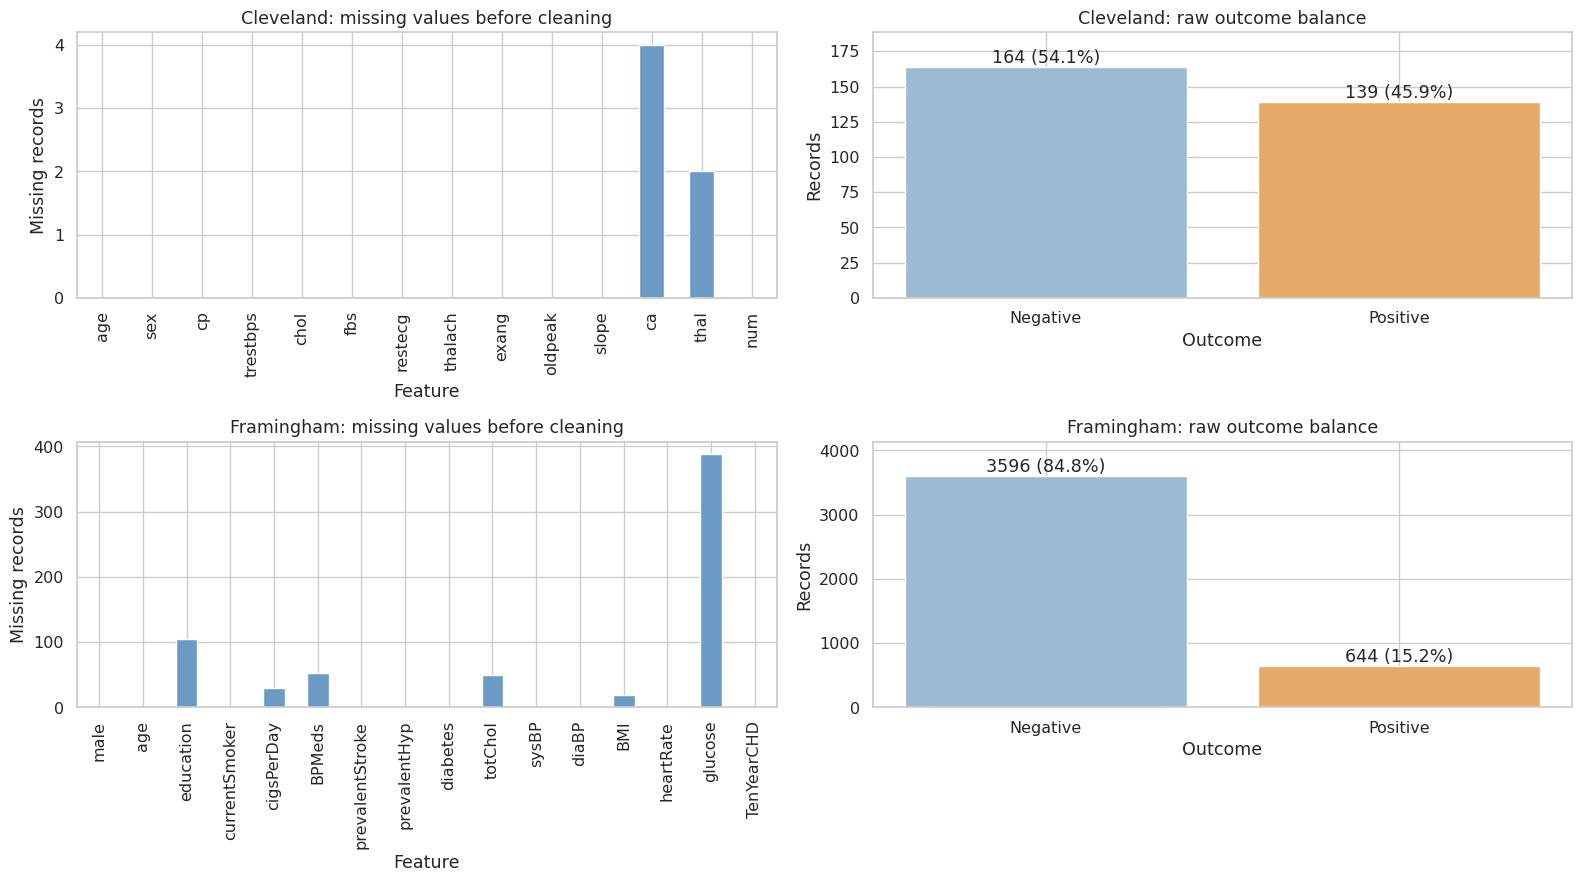

In [6]:
def binary_outcome(dataset, frame):
    return (frame['num'] > 0).astype(int) if dataset == 'Cleveland' else frame['TenYearCHD']

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for row, (dataset, frame) in enumerate(raw.items()):
    missing = frame.isna().sum()
    missing.plot.bar(ax=axes[row, 0], color='#6b9ac4')
    axes[row, 0].set(title=f'{dataset}: missing values before cleaning',
                     xlabel='Feature', ylabel='Missing records')
    counts = binary_outcome(dataset, frame).value_counts().reindex([0, 1])
    axes[row, 1].bar(['Negative', 'Positive'], counts, color=['#9bbbd4', '#e7aa68'])
    for i, count in enumerate(counts):
        axes[row, 1].text(i, count, f'{count} ({count / counts.sum():.1%})', ha='center', va='bottom')
    axes[row, 1].set(title=f'{dataset}: raw outcome balance', ylabel='Records', xlabel='Outcome')
    axes[row, 1].set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.show()


Missingness is feature-dependent rather than a single common missing block, so complete-case deletion can change the population. The raw outcome bars already show that Framingham is much more imbalanced than Cleveland; accuracy alone will be misleading there.

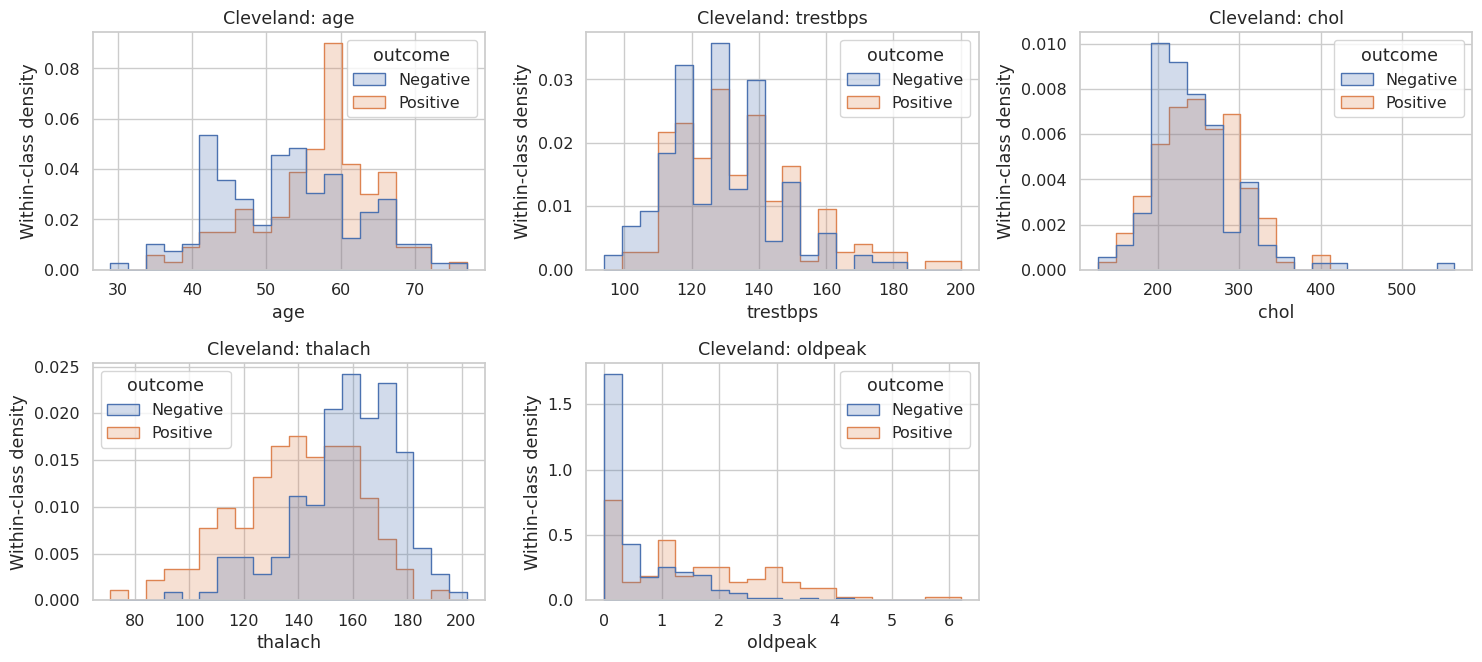

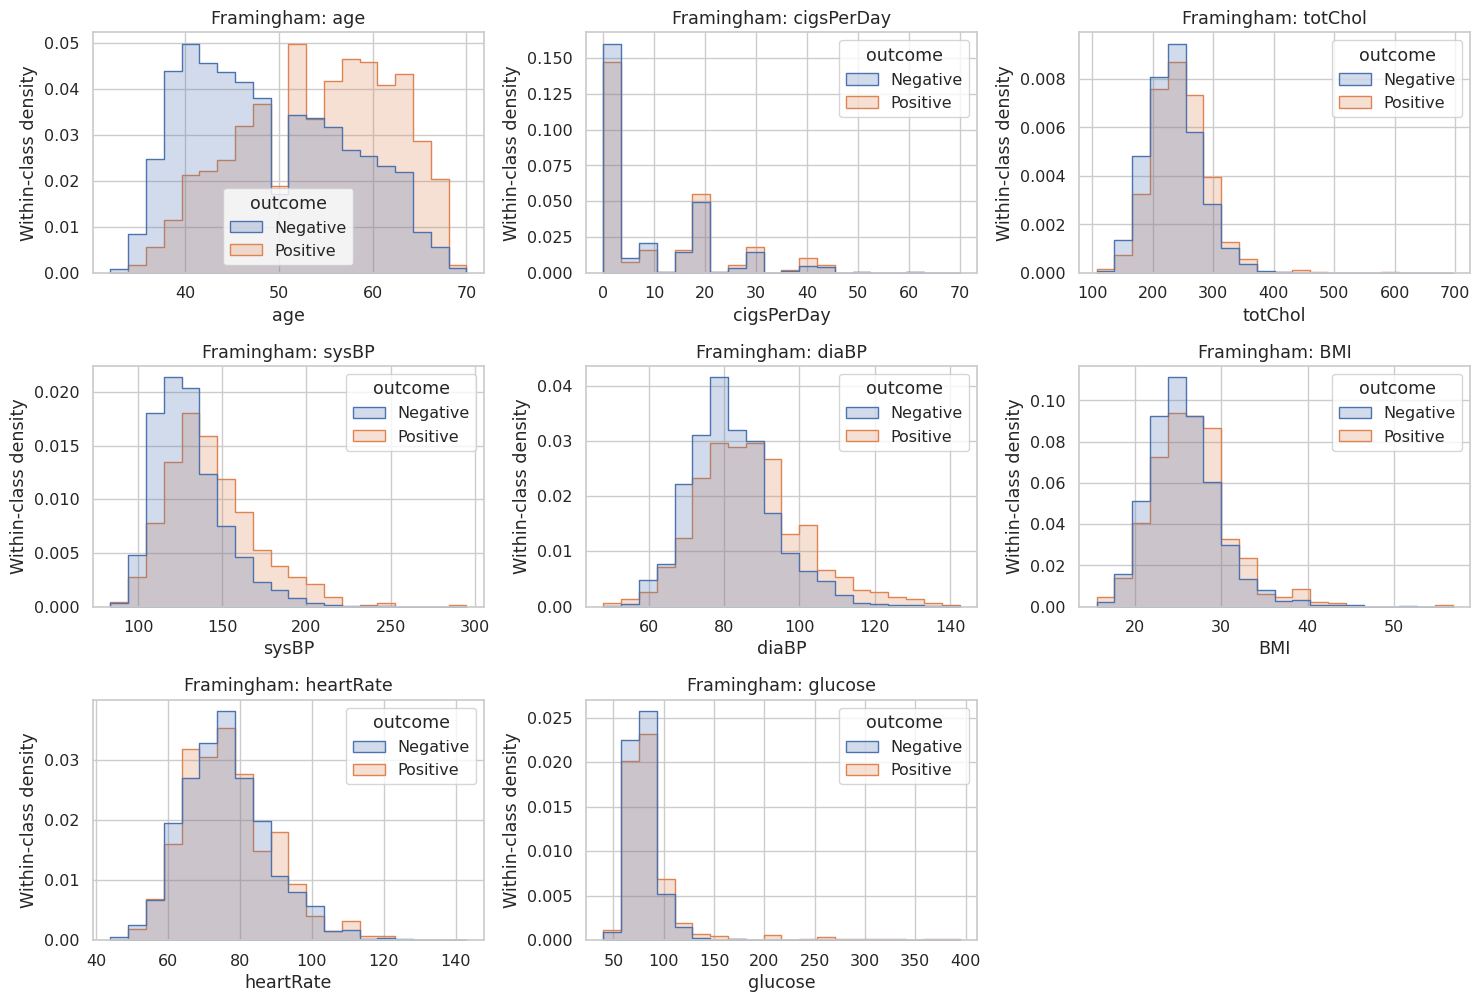

In [7]:
CONTINUOUS = {
    'Cleveland': ['age', 'trestbps', 'chol', 'thalach', 'oldpeak'],
    'Framingham': ['age', 'cigsPerDay', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose'],
}
CATEGORICAL = {
    'Cleveland': ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal'],
    'Framingham': ['male', 'education', 'currentSmoker', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes'],
}
for dataset, frame in raw.items():
    view = frame.assign(outcome=binary_outcome(dataset, frame).map({0: 'Negative', 1: 'Positive'}))
    columns = CONTINUOUS[dataset]
    fig, axes = plt.subplots((len(columns) + 2) // 3, 3, figsize=(15, 3.4 * ((len(columns) + 2) // 3)))
    for ax, feature in zip(axes.flat, columns):
        sns.histplot(data=view, x=feature, hue='outcome', bins=20, stat='density',
                     common_norm=False, element='step', ax=ax)
        ax.set(title=f'{dataset}: {feature}', ylabel='Within-class density')
    for ax in list(axes.flat)[len(columns):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()


The continuous-feature histograms compare *within-class* distributions, not raw class sizes. Overlap is substantial, and skewed variables such as cigarette count and ST depression are not made Gaussian by standardization.

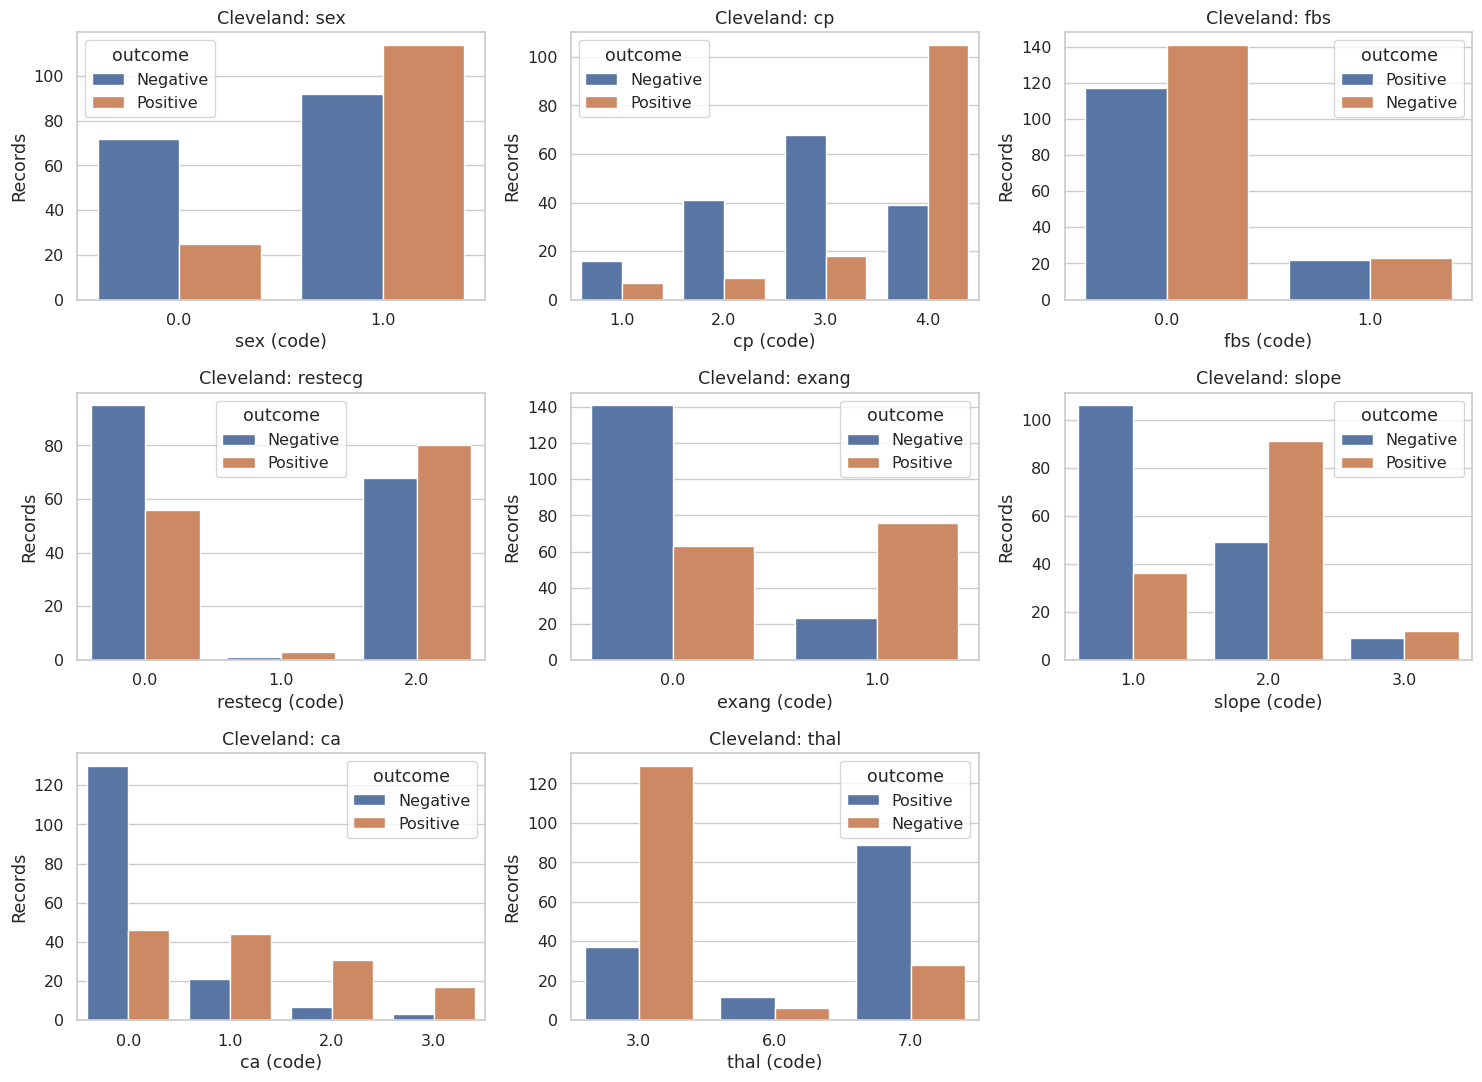

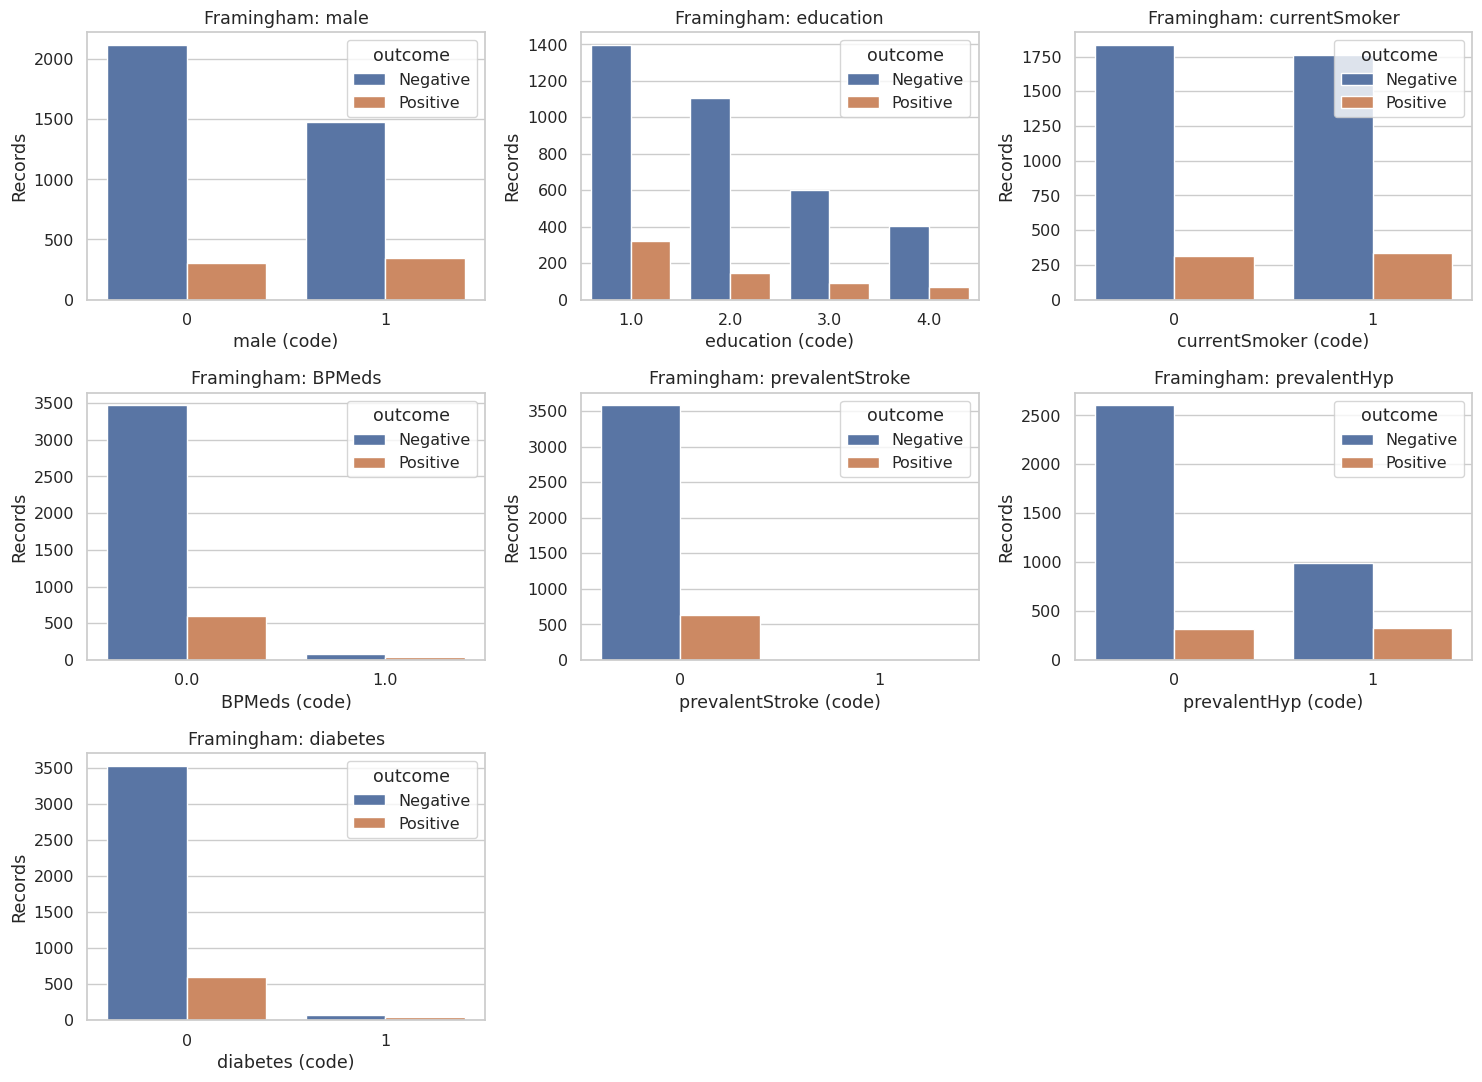

In [8]:
for dataset, frame in raw.items():
    view = frame.assign(outcome=binary_outcome(dataset, frame).map({0: 'Negative', 1: 'Positive'}))
    columns = CATEGORICAL[dataset]
    fig, axes = plt.subplots(3, 3, figsize=(15, 11))
    for ax, feature in zip(axes.flat, columns):
        sns.countplot(data=view, x=feature, hue='outcome', ax=ax)
        ax.set(title=f'{dataset}: {feature}', xlabel=f'{feature} (code)', ylabel='Records')
    for ax in list(axes.flat)[len(columns):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()


These category counts retain the original coding and show small subgroups that may be poorly represented in a 20% test set. Counts reflect prevalence as well as association; they do not identify causal risk factors.

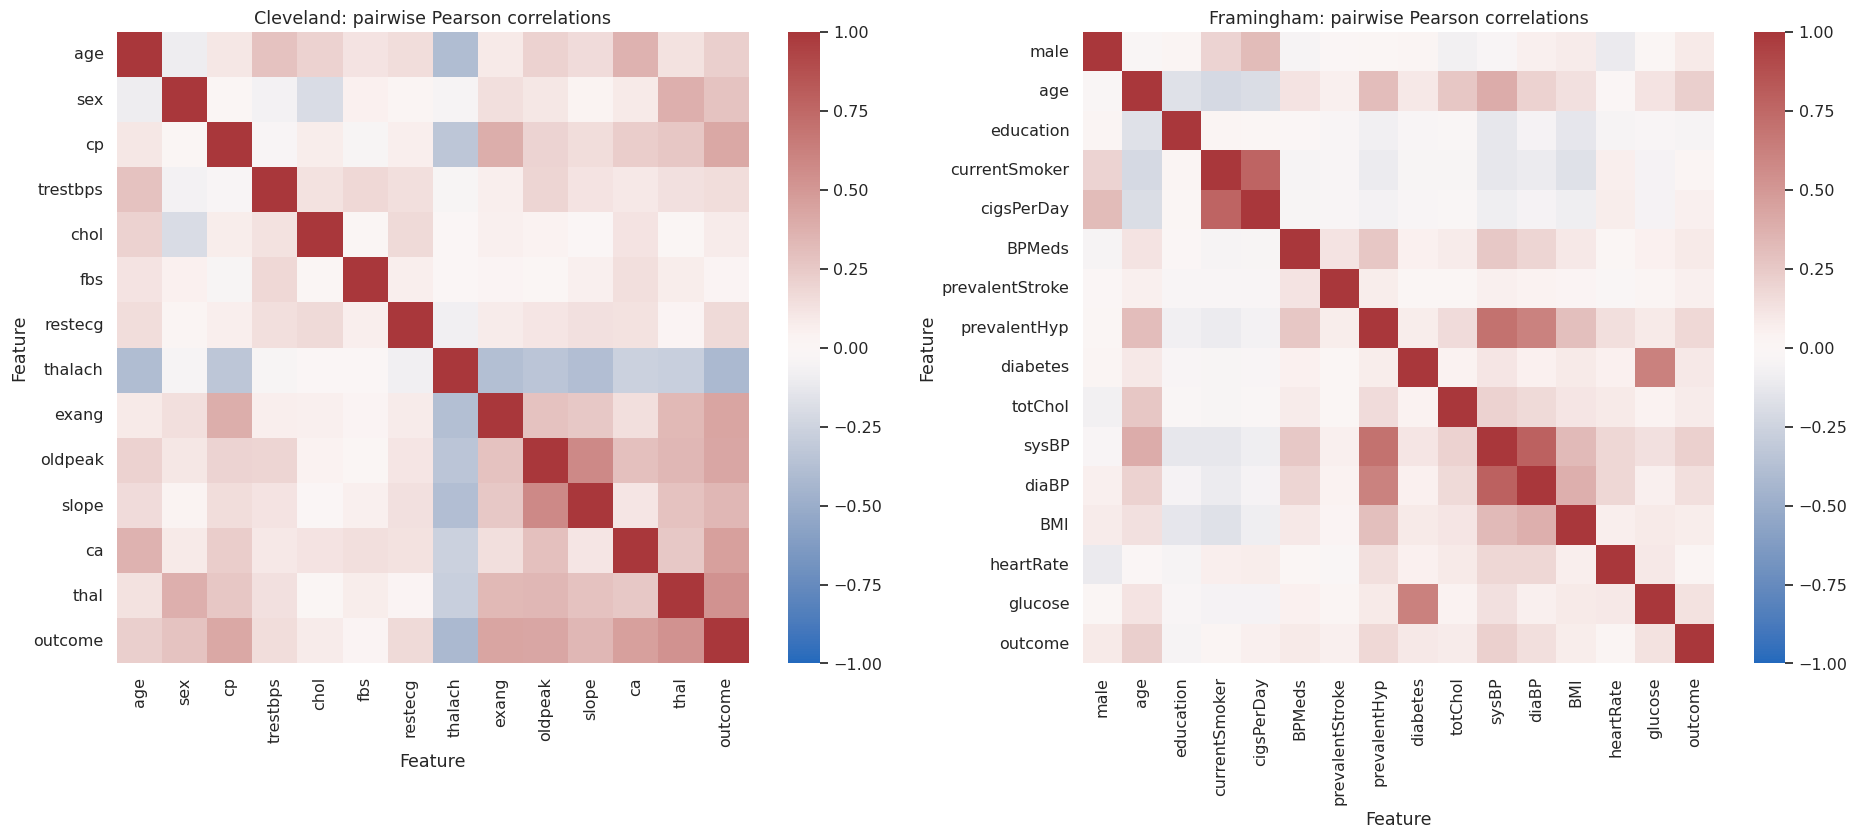

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(19, 8))
for ax, (dataset, frame) in zip(axes, raw.items()):
    view = frame.drop(columns=['num' if dataset == 'Cleveland' else 'TenYearCHD'])
    view = view.assign(outcome=binary_outcome(dataset, frame))
    sns.heatmap(view.corr(), cmap='vlag', center=0, vmin=-1, vmax=1, square=True, ax=ax)
    ax.set(title=f'{dataset}: pairwise Pearson correlations', xlabel='Feature', ylabel='Feature')
plt.tight_layout()
plt.show()


Pairwise correlations use the available observations for each pair, not one fixed complete-case sample. Correlations of category codes are only descriptive: their numerical spacing is arbitrary. Correlated blood-pressure and smoking variables can also share SHAP credit.

## 3. Cleaning — paper §2.1

Following the paper, replace Cleveland `?` with missing values (done during reading), drop incomplete rows, remove duplicates, and define Cleveland disease as `num > 0`. We deduplicate **before** binarization so two distinct raw diagnoses are not accidentally treated as duplicate source records. The assertions below are hard gates: stop rather than model a different extract.

,Dataset,Raw,Complete cases,Deduplicated
0,Cleveland,303,297,297
1,Framingham,4240,3658,3658


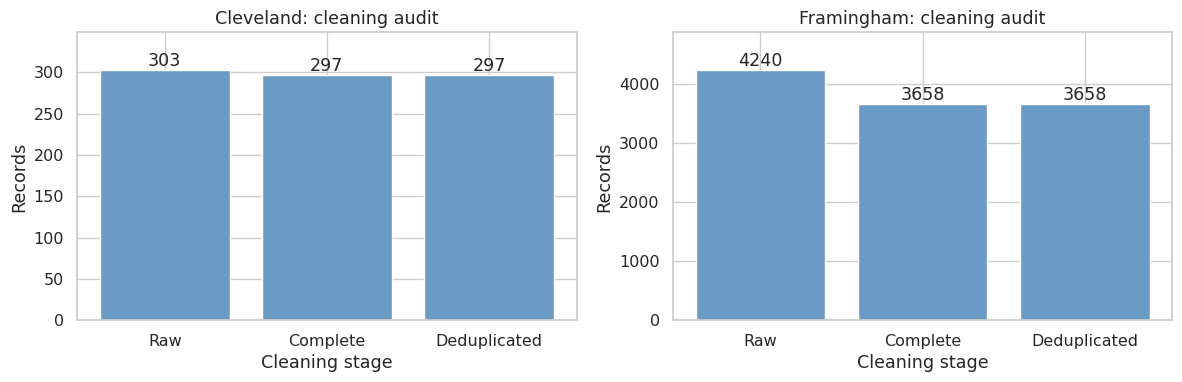

Cleveland: 297 records; 137 positive (46.13%)
Framingham: 3658 records; 557 positive (15.23%)


In [10]:
clean, cleaning_rows = {}, []
EXPECTED = {'Cleveland': (297, 137), 'Framingham': (3658, 557)}
for dataset, frame in raw.items():
    complete = frame.dropna()
    unique = complete.drop_duplicates().copy()
    cleaning_rows.append([dataset, len(frame), len(complete), len(unique)])
    outcome = binary_outcome(dataset, unique)
    target = 'num' if dataset == 'Cleveland' else 'TenYearCHD'
    clean[dataset] = unique.drop(columns=target).assign(outcome=outcome).reset_index(drop=True)
    assert (len(unique), int(outcome.sum())) == EXPECTED[dataset], dataset
cleaning_table = pd.DataFrame(cleaning_rows, columns=['Dataset', 'Raw', 'Complete cases', 'Deduplicated'])
display(cleaning_table)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (_, row) in zip(axes, cleaning_table.iterrows()):
    ax.bar(['Raw', 'Complete', 'Deduplicated'], row.iloc[1:].astype(int), color='#6b9ac4')
    for i, count in enumerate(row.iloc[1:]):
        ax.text(i, count, str(count), ha='center', va='bottom')
    ax.set(title=f'{row.Dataset}: cleaning audit', ylabel='Records', xlabel='Cleaning stage')
    ax.set_ylim(0, row.Raw * 1.15)
plt.tight_layout()
plt.show()
for dataset, frame in clean.items():
    print(f'{dataset}: {len(frame)} records; {frame.outcome.sum()} positive ({frame.outcome.mean():.2%})')


The gates require 297/137 Cleveland records/positives and 3,658/557 Framingham records/positives, matching the intended extracts. Complete-case removal is an explicit reproduction choice, not a recommendation: selection bias remains possible.

## 4. Stratified 80/20 split — paper §2.2

The paper preserves class proportions and reports train/test sizes 237/60 and 2,926/732. We choose seed 42 because its split seed is not specified. The test data are never resampled or used for hyperparameter selection.

,Dataset,Partition,N,Positive fraction
0,Cleveland,Train,237,0.459916
1,Cleveland,Test,60,0.466667
2,Framingham,Train,2926,0.152427
3,Framingham,Test,732,0.151639


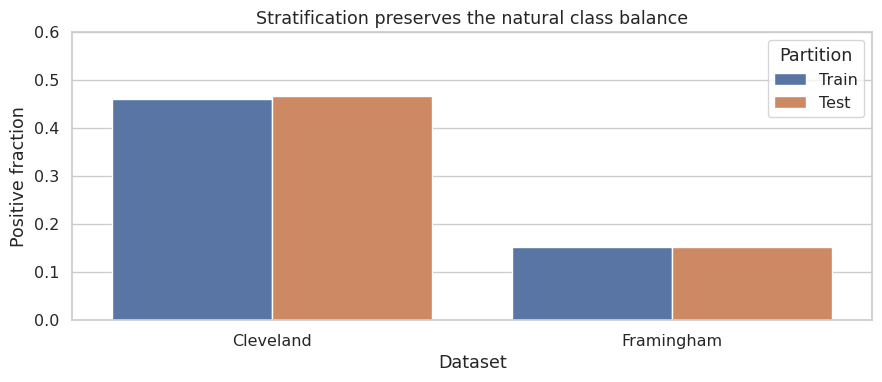

In [11]:
splits, balance_rows = {}, []
for dataset, frame in clean.items():
    X, y = frame.drop(columns='outcome'), frame.outcome
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=SEED)
    expected_sizes = (237, 60) if dataset == 'Cleveland' else (2926, 732)
    assert (len(y_train), len(y_test)) == expected_sizes
    assert set(X_train.index).isdisjoint(X_test.index)
    splits[dataset] = (X_train, X_test, y_train, y_test)
    for partition, labels in [('Train', y_train), ('Test', y_test)]:
        balance_rows.append([dataset, partition, len(labels), labels.mean()])
split_table = pd.DataFrame(balance_rows, columns=['Dataset', 'Partition', 'N', 'Positive fraction'])
display(split_table)
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=split_table, x='Dataset', y='Positive fraction', hue='Partition', ax=ax)
ax.set(title='Stratification preserves the natural class balance', ylabel='Positive fraction', ylim=(0, 0.6))
plt.tight_layout()
plt.show()


The proportions agree closely, but Cleveland's 60-patient test set makes each error consequential. Preserving Framingham's natural test prevalence is essential for interpreting precision and calibration.

## 5. Training-only class balancing and scaling — paper §2.2

Use an imbalanced-learn pipeline ordered **SMOTE → RandomUnderSampler → StandardScaler → classifier**. Exact intermediate sampler ratios are unreported: our assumption is default SMOTE (`k_neighbors=5`, minority/majority=1), followed by an undersampler targeting 1:1, which is consequently a no-op. We do not invent an unreported intermediate ratio. Scaling after resampling follows the prose, even though SMOTE's raw-unit distance can be dominated by large-scale features.

The following diagnostic fits use *only* the outer training partition and never feed fitted transforms into the model-selection step. Later, each pipeline is fitted afresh within every CV training fold, preventing synthetic samples or fitted means from leaking across validation boundaries.

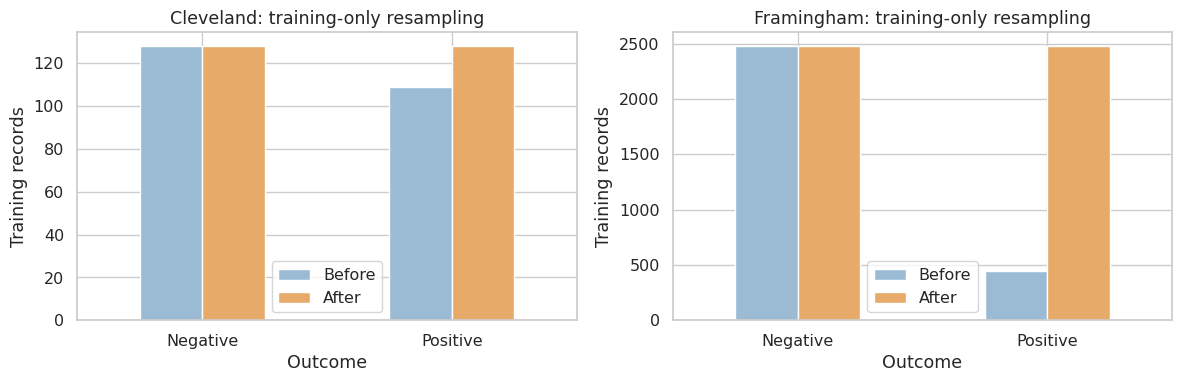

In [12]:
resampling_views = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (dataset, (X_train, _, y_train, _)) in zip(axes, splits.items()):
    sampled_X, sampled_y = SMOTE(random_state=SEED).fit_resample(X_train, y_train)
    balanced_X, balanced_y = RandomUnderSampler(random_state=SEED).fit_resample(sampled_X, sampled_y)
    assert balanced_y.value_counts().nunique() == 1
    resampling_views[dataset] = (sampled_X, sampled_y, balanced_X, balanced_y)
    counts = pd.DataFrame({'Before': y_train.value_counts(), 'After': balanced_y.value_counts()})
    counts.index = ['Negative', 'Positive']
    counts.plot.bar(ax=ax, rot=0, color=['#9bbbd4', '#e7aa68'])
    ax.set(title=f'{dataset}: training-only resampling', xlabel='Outcome', ylabel='Training records')
plt.tight_layout()
plt.show()


SMOTE adds far more observations to Framingham than to Cleveland. Balanced training priors differ sharply from Framingham's test prior, so a good AUROC need not imply calibrated probabilities at the original prevalence.

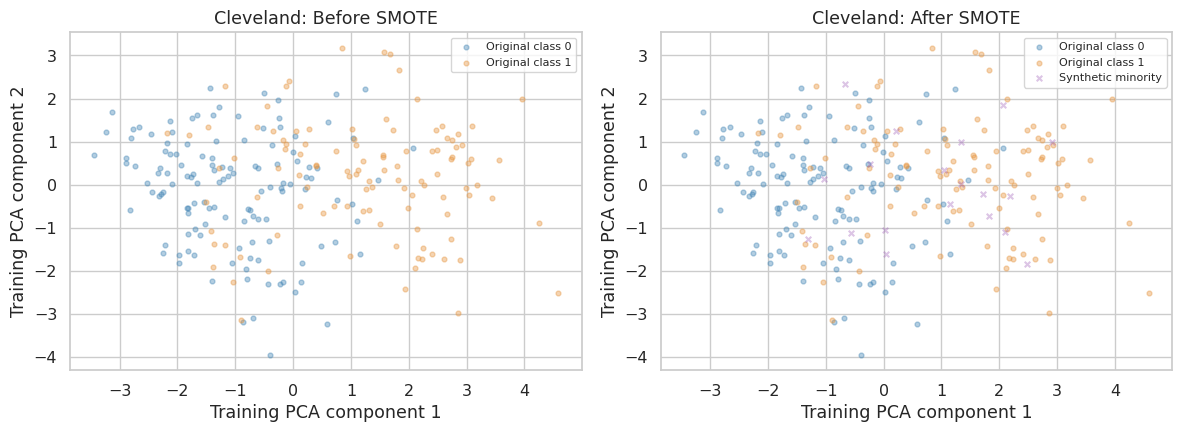

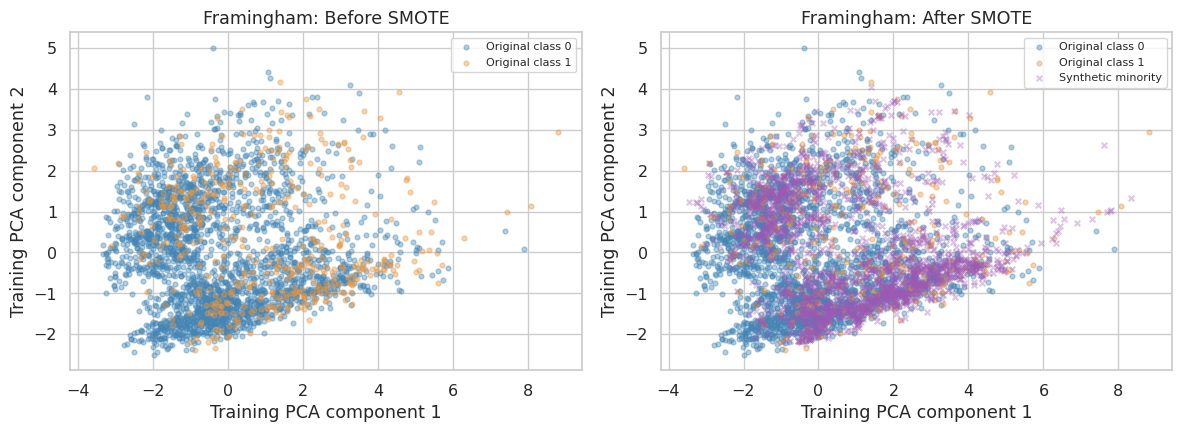

In [13]:
for dataset, (X_train, _, y_train, _) in splits.items():
    sampled_X, sampled_y, _, _ = resampling_views[dataset]
    diagnostic_scale = StandardScaler().fit(X_train)
    pca = PCA(n_components=2, svd_solver='full').fit(diagnostic_scale.transform(X_train))
    original = pca.transform(diagnostic_scale.transform(X_train))
    augmented = pca.transform(diagnostic_scale.transform(sampled_X))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for label, color in [(0, '#4385b5'), (1, '#e69540')]:
        mask = y_train.to_numpy() == label
        for ax in axes:
            ax.scatter(original[mask, 0], original[mask, 1], s=12,
                       alpha=0.4, color=color, label=f'Original class {label}')
    synthetic = augmented[len(X_train):]
    axes[1].scatter(synthetic[:, 0], synthetic[:, 1], s=16, alpha=0.35,
                    color='#9b59b6', marker='x', label='Synthetic minority')
    for ax, stage in zip(axes, ['Before SMOTE', 'After SMOTE']):
        ax.set(title=f'{dataset}: {stage}', xlabel='Training PCA component 1', ylabel='Training PCA component 2')
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


Purple crosses mark synthetic observations in a common PCA coordinate system fitted on the original training set. This separate standardized PCA is a **visual diagnostic only**: the model pipeline still performs SMOTE before its own scaler. Interpolation also makes fractional categorical codes, an important limitation of ordinary SMOTE here.

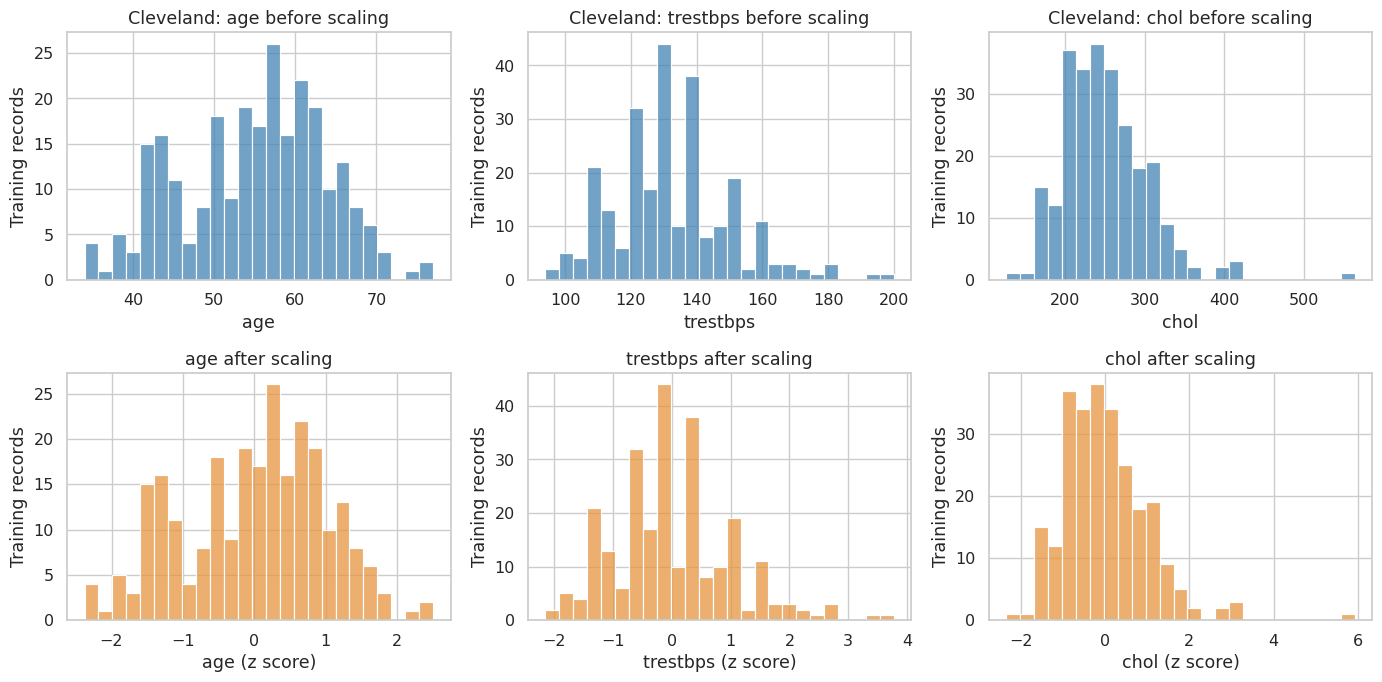

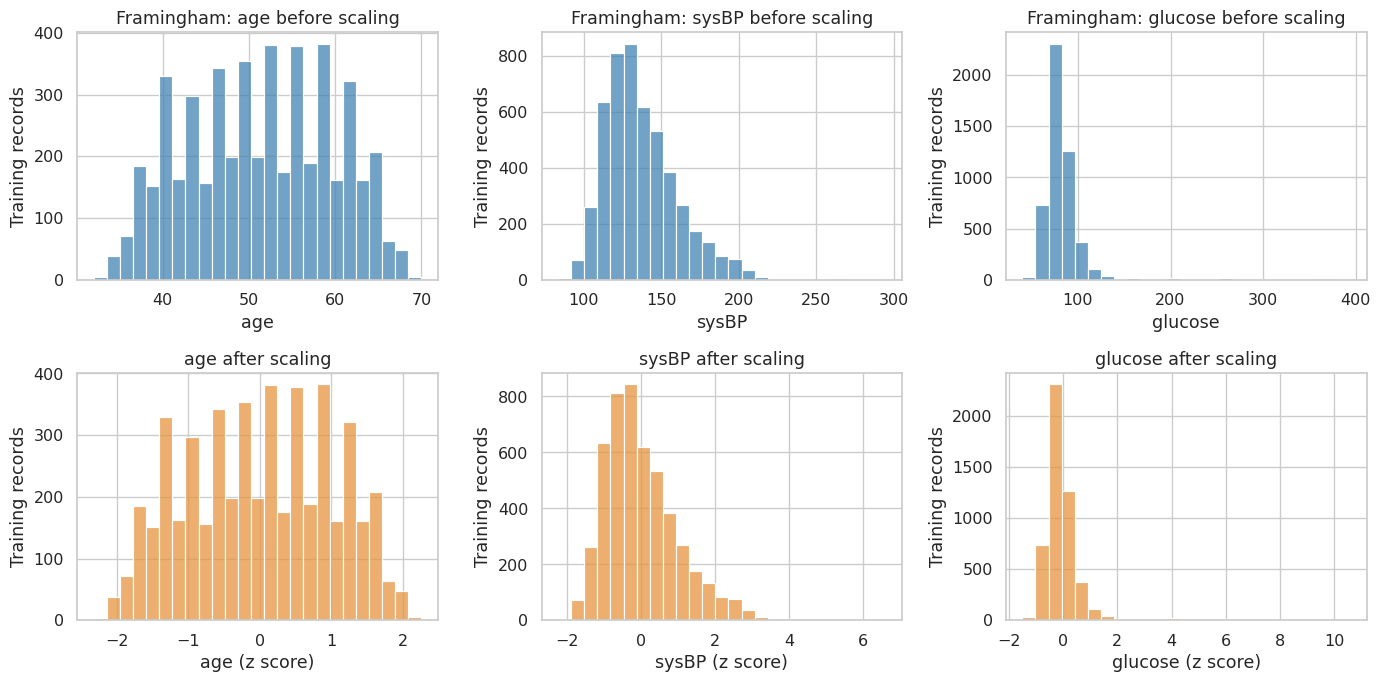

In [14]:
for dataset in splits:
    _, _, balanced_X, _ = resampling_views[dataset]
    scaled = pd.DataFrame(StandardScaler().fit_transform(balanced_X), columns=balanced_X.columns)
    features = ['age', 'trestbps', 'chol'] if dataset == 'Cleveland' else ['age', 'sysBP', 'glucose']
    fig, axes = plt.subplots(2, 3, figsize=(14, 7))
    for col, feature in enumerate(features):
        sns.histplot(balanced_X[feature], bins=25, ax=axes[0, col], color='#4385b5')
        sns.histplot(scaled[feature], bins=25, ax=axes[1, col], color='#e69540')
        axes[0, col].set(title=f'{dataset}: {feature} before scaling', ylabel='Training records')
        axes[1, col].set(title=f'{feature} after scaling', xlabel=f'{feature} (z score)', ylabel='Training records')
    plt.tight_layout()
    plt.show()


Standardization changes units, not shape. LR, KNN, and the NN are sensitive to scale; we keep the same preprocessing for the tree models to follow the paper consistently.

## 6. Five models — paper §2.3

### Reported best settings (used for held-out evaluation and stability)

| Model | Framingham | Cleveland |
|---|---|---|
| LR | C=0.01, L2, liblinear | C=0.001, L2, liblinear |
| RF | gini, depth=8, sqrt features, 75 trees | entropy, depth=12, sqrt features, 200 trees |
| KNN | Manhattan, k=15, uniform | Manhattan, k=15, distance |
| XGBoost | colsample=0.5, lr=0.01, depth=3, child weight=1, 50 trees, subsample=0.5 | colsample=0.5, lr=0.1, depth=3, child weight=3, 50 trees, subsample=0.8 |
| NN (**our assumption**) | input–32–16–1, ReLU; BCEWithLogits; Adam lr=0.001; 100 full-batch epochs | same |

Source: [§2.3](https://pmc.ncbi.nlm.nih.gov/articles/PMC13298444/#sec2dot3-epidemiologia-07-00075). The paper names PyTorch but does not specify enough NN details for exact replication. All unlisted estimator options use the pinned library defaults; XGBoost uses CPU histogram trees and logloss, RF/KNN/XGBoost use one worker. The NN never uses test-based early stopping.

In [15]:
PAPER_PARAMS = {
    'Framingham': {
        'LR': dict(C=0.01, penalty='l2', solver='liblinear'),
        'RF': dict(criterion='gini', max_depth=8, max_features='sqrt', n_estimators=75),
        'KNN': dict(metric='manhattan', n_neighbors=15, weights='uniform'),
        'XGB': dict(colsample_bytree=0.5, learning_rate=0.01, max_depth=3,
                    min_child_weight=1, n_estimators=50, subsample=0.5),
    },
    'Cleveland': {
        'LR': dict(C=0.001, penalty='l2', solver='liblinear'),
        'RF': dict(criterion='entropy', max_depth=12, max_features='sqrt', n_estimators=200),
        'KNN': dict(metric='manhattan', n_neighbors=15, weights='distance'),
        'XGB': dict(colsample_bytree=0.5, learning_rate=0.1, max_depth=3,
                    min_child_weight=3, n_estimators=50, subsample=0.8),
    },
}


In [16]:
class TorchClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, random_state=SEED, epochs=100):
        self.random_state = random_state
        self.epochs = epochs

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.n_features_in_ = X.shape[1]
        inputs = torch.tensor(np.asarray(X), dtype=torch.float32)
        labels = torch.tensor(np.asarray(y), dtype=torch.float32).reshape(-1, 1)
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(self.random_state)
            self.network_ = torch.nn.Sequential(
                torch.nn.Linear(self.n_features_in_, 32), torch.nn.ReLU(),
                torch.nn.Linear(32, 16), torch.nn.ReLU(), torch.nn.Linear(16, 1))
            optimizer = torch.optim.Adam(self.network_.parameters(), lr=1e-3)
            loss_function = torch.nn.BCEWithLogitsLoss()
            self.losses_ = []
            self.network_.train()
            for _ in range(self.epochs):
                optimizer.zero_grad()
                loss = loss_function(self.network_(inputs), labels)
                loss.backward()
                optimizer.step()
                self.losses_.append(loss.item())
        self.network_.eval()
        return self

    def predict_proba(self, X):
        with torch.no_grad():
            inputs = torch.tensor(np.asarray(X), dtype=torch.float32)
            positive = torch.sigmoid(self.network_(inputs)).numpy().ravel()
        return np.column_stack([1 - positive, positive])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


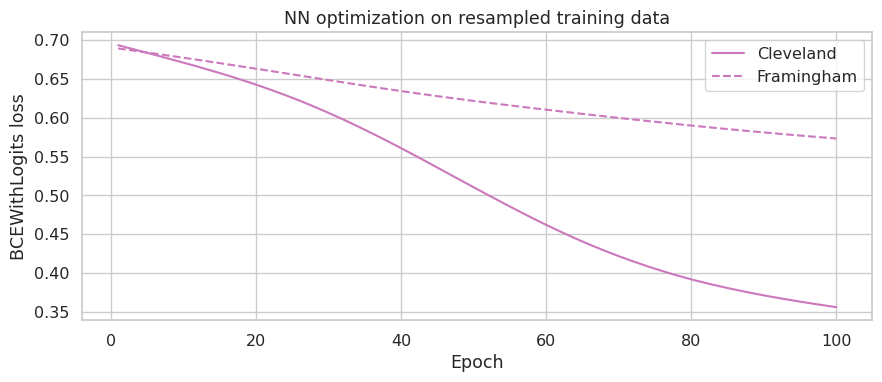

In [17]:
def make_pipeline(dataset, model, seed=SEED, balanced=True):
    constructors = {
        'LR': lambda: LogisticRegression(max_iter=2000, random_state=seed),
        'RF': lambda: RandomForestClassifier(random_state=seed, n_jobs=1),
        'KNN': lambda: KNeighborsClassifier(n_jobs=1),
        'XGB': lambda: XGBClassifier(random_state=seed, n_jobs=1,
            objective='binary:logistic', eval_metric='logloss', tree_method='hist'),
        'NN': lambda: TorchClassifier(random_state=seed),
    }
    estimator = constructors[model]()
    estimator.set_params(**PAPER_PARAMS[dataset].get(model, {}))
    steps = []
    if balanced:
        steps += [('smote', SMOTE(random_state=seed)),
                  ('undersample', RandomUnderSampler(random_state=seed))]
    return Pipeline(steps + [('scale', StandardScaler()), ('model', estimator)])

fitted, probabilities = {}, {}
for dataset, (X_train, X_test, y_train, y_test) in splits.items():
    for model in MODELS:
        pipeline = make_pipeline(dataset, model).fit(X_train, y_train)
        fitted[dataset, model] = pipeline
        probabilities[dataset, model] = pipeline.predict_proba(X_test)[:, 1]
        assert np.isfinite(probabilities[dataset, model]).all()
fig, ax = plt.subplots(figsize=(9, 4))
for dataset, style in [('Cleveland', '-'), ('Framingham', '--')]:
    ax.plot(range(1, 101), fitted[dataset, 'NN'].named_steps['model'].losses_,
            style, color=COLORS['NN'], label=dataset)
ax.set(title='NN optimization on resampled training data', xlabel='Epoch', ylabel='BCEWithLogits loss')
ax.legend()
plt.tight_layout()
plt.show()


Decreasing training loss verifies optimization, not generalization. The NN's different result from the paper could arise from the unspecified architecture or optimizer; we will not adjust them to match a held-out score.

### Small five-fold search — explicitly our assumption

The paper reports GridSearchCV but not its grid or scoring criterion. Our separate demonstration uses five stratified shuffled folds (seed 42), AUROC scoring, and a small grid including the reported point: LR C∈{0.001,0.01,0.1}; RF trees∈{75,200}; KNN weights∈{uniform,distance}; XGBoost lr∈{0.01,0.1} × child weight∈{1,3}. Everything else stays at the reported settings. This is **not** reconstruction of the authors' search, and its winners do not replace the fixed models evaluated below.

,Dataset,Model,Best CV AUROC,Selected parameters
0,Cleveland,LR,0.883309,{'model__C': 0.001}
1,Cleveland,RF,0.882386,{'model__n_estimators': 200}
2,Cleveland,KNN,0.884583,{'model__weights': 'uniform'}
3,Cleveland,XGB,0.899889,"{'model__learning_rate': 0.1, 'model__min_chil..."
4,Framingham,LR,0.712901,{'model__C': 0.001}
5,Framingham,RF,0.685380,{'model__n_estimators': 75}
6,Framingham,KNN,0.629846,{'model__weights': 'distance'}
7,Framingham,XGB,0.692902,"{'model__learning_rate': 0.01, 'model__min_chi..."


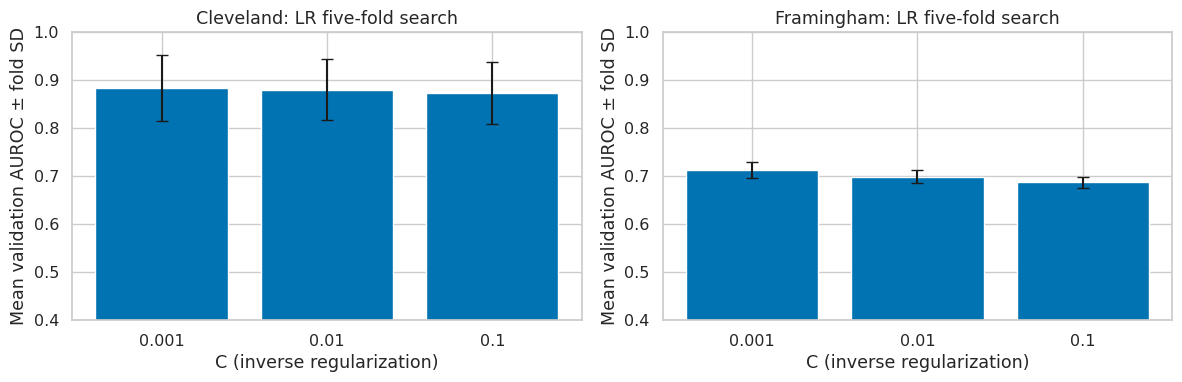

In [18]:
GRIDS = {
    'LR': {'model__C': [0.001, 0.01, 0.1]},
    'RF': {'model__n_estimators': [75, 200]},
    'KNN': {'model__weights': ['uniform', 'distance']},
    'XGB': {'model__learning_rate': [0.01, 0.1], 'model__min_child_weight': [1, 3]},
}
searches, search_rows = {}, []
for dataset, (X_train, _, y_train, _) in splits.items():
    for model, grid in GRIDS.items():
        search = GridSearchCV(make_pipeline(dataset, model), grid, scoring='roc_auc',
            cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
            n_jobs=1, error_score='raise', refit=True).fit(X_train, y_train)
        searches[dataset, model] = search
        search_rows.append([dataset, model, search.best_score_, search.best_params_])
display(pd.DataFrame(search_rows, columns=['Dataset', 'Model', 'Best CV AUROC', 'Selected parameters']))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, dataset in zip(axes, splits):
    result = pd.DataFrame(searches[dataset, 'LR'].cv_results_)
    ax.bar(result.param_model__C.astype(str), result.mean_test_score,
           yerr=result.std_test_score, color=COLORS['LR'], capsize=4)
    ax.set(title=f'{dataset}: LR five-fold search', xlabel='C (inverse regularization)',
           ylabel='Mean validation AUROC ± fold SD', ylim=(0.4, 1))
plt.tight_layout()
plt.show()


The bars summarize validation-fold AUROC, with descriptive fold SD rather than a confidence interval. Selection uses only outer training data, and the small candidate set makes this a transparent sensitivity check rather than a claim to have found globally optimal settings.

## 7. Untouched-test evaluation — paper §2.3, Tables 2–3

Compute accuracy, positive-class precision/recall/F1, MCC, AUROC, and Brier. Predictions use a **0.5 threshold** (our assumption); undefined precision is set to zero. Brier is mean squared probability error (lower is better), while AUROC measures discrimination independent of this threshold. No probability recalibration is fitted to the test labels.

In [19]:
METRICS = ['Accuracy', 'Precision', 'Recall', 'F1', 'MCC', 'AUROC', 'Brier']

def evaluate(y, probability):
    prediction = (np.asarray(probability) >= 0.5).astype(int)
    return dict(zip(METRICS, [
        accuracy_score(y, prediction), precision_score(y, prediction, zero_division=0),
        recall_score(y, prediction, zero_division=0), f1_score(y, prediction, zero_division=0),
        matthews_corrcoef(y, prediction), roc_auc_score(y, probability),
        brier_score_loss(y, probability)]))

metric_rows = []
for (dataset, model), probability in probabilities.items():
    metric_rows.append(dict(Dataset=dataset, Model=model,
                           **evaluate(splits[dataset][3], probability)))
ours = pd.DataFrame(metric_rows)
display(ours.round(4))


,Dataset,Model,Accuracy,Precision,Recall,F1,MCC,AUROC,Brier
0,Cleveland,LR,0.9000,0.9231,0.8571,0.8889,0.8000,0.9509,0.2084
1,Cleveland,RF,0.8500,0.8519,0.8214,0.8364,0.6984,0.9408,0.1091
2,Cleveland,KNN,0.8333,0.8750,0.7500,0.8077,0.6683,0.9554,0.0923
3,Cleveland,XGB,0.8333,0.8750,0.7500,0.8077,0.6683,0.9330,0.1134
4,Cleveland,NN,0.8333,0.8462,0.7857,0.8148,0.6652,0.9487,0.0954
5,Framingham,LR,0.6393,0.2258,0.5676,0.3231,0.1623,0.6581,0.2191
6,Framingham,RF,0.7568,0.2781,0.3784,0.3206,0.1798,0.6810,0.1704
7,Framingham,KNN,0.6667,0.2170,0.4595,0.2948,0.1253,0.6295,0.2064
8,Framingham,XGB,0.7117,0.2642,0.5045,0.3467,0.2003,0.6898,0.2232
9,Framingham,NN,0.6325,0.2117,0.5225,0.3013,0.1295,0.6456,0.2151


The seven metrics distinguish ranking, decisions, and probability quality. In imbalanced Framingham, compare accuracy with the negative-class baseline and inspect precision and Brier before treating a high accuracy as useful.

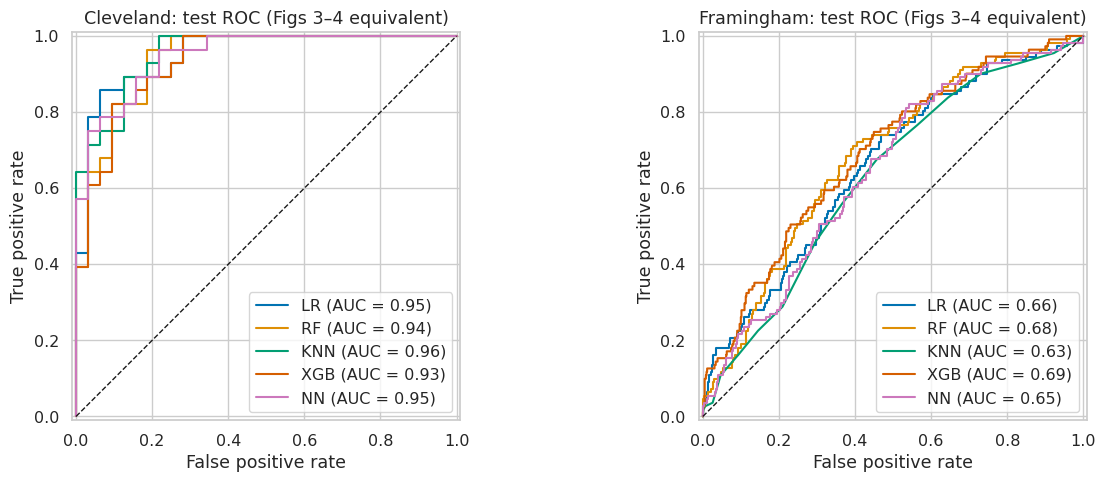

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, dataset in zip(axes, splits):
    y_test = splits[dataset][3]
    for model in MODELS:
        RocCurveDisplay.from_predictions(y_test, probabilities[dataset, model],
            name=model, color=COLORS[model], ax=ax)
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1)
    ax.set(title=f'{dataset}: test ROC (Figs 3–4 equivalent)',
           xlabel='False positive rate', ylabel='True positive rate')
plt.tight_layout()
plt.show()


ROC curves use the same test patients for every model, enabling paired visual comparison. Small changes in a few Cleveland rankings can move its AUROC noticeably; these single-split curves are not uncertainty estimates.

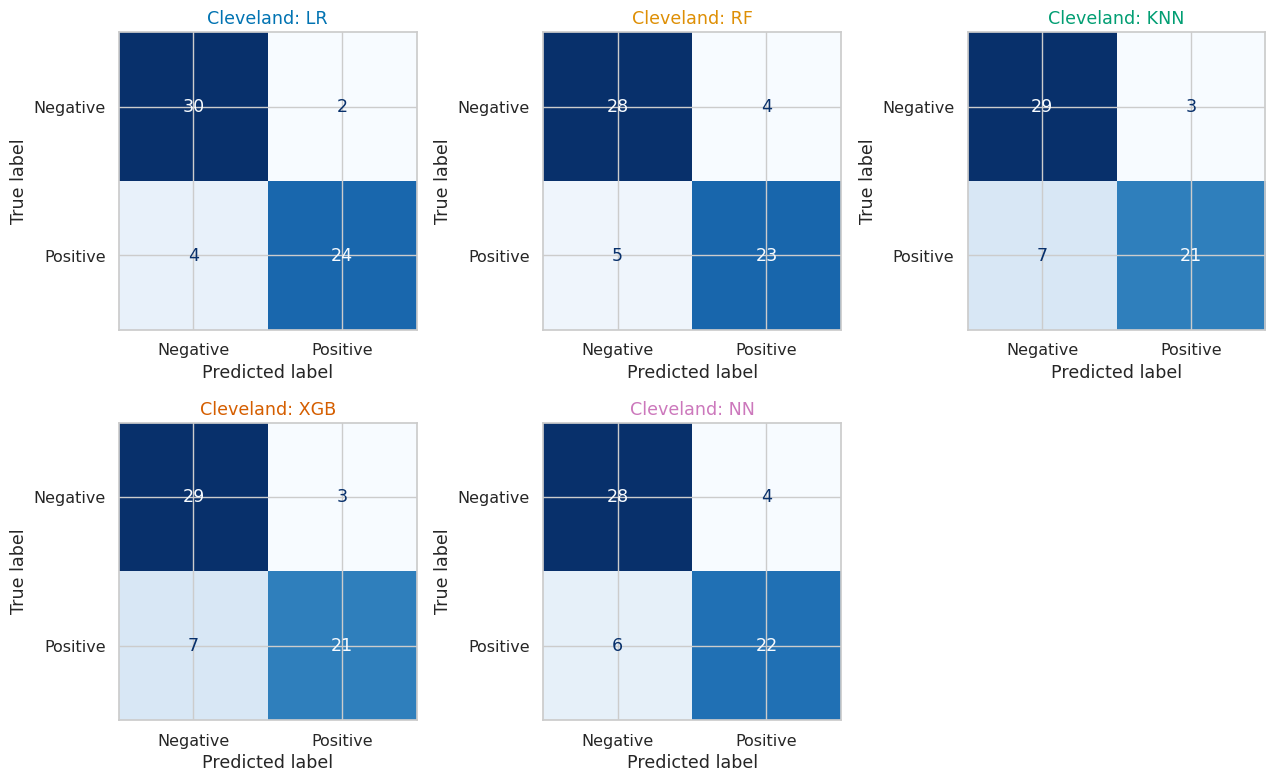

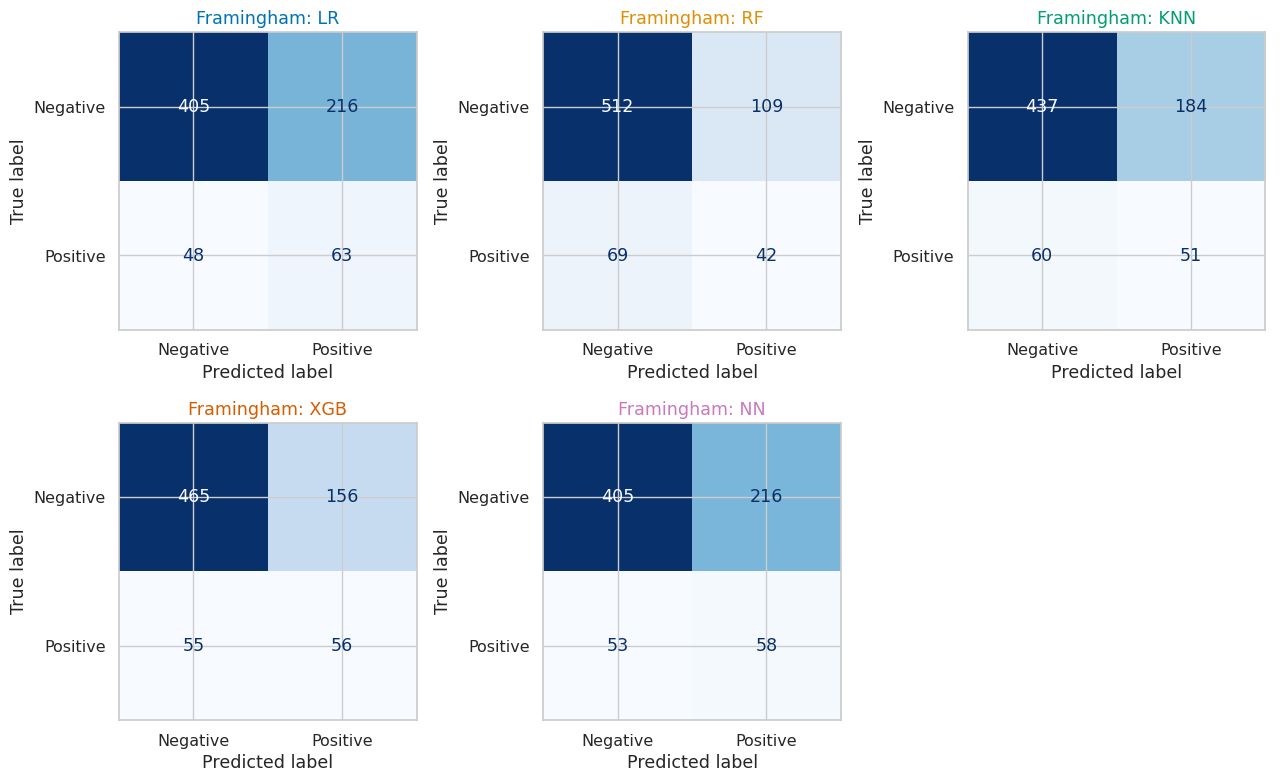

In [21]:
for dataset in splits:
    fig, axes = plt.subplots(2, 3, figsize=(13, 8))
    for ax, model in zip(axes.flat, MODELS):
        prediction = (probabilities[dataset, model] >= 0.5).astype(int)
        ConfusionMatrixDisplay.from_predictions(splits[dataset][3], prediction,
            labels=[0, 1], display_labels=['Negative', 'Positive'],
            colorbar=False, cmap='Blues', ax=ax)
        ax.set_title(f'{dataset}: {model}', color=COLORS[model])
    axes.flat[-1].axis('off')
    plt.tight_layout()
    plt.show()


Confusion matrices show the actual false-positive/false-negative trade-off at 0.5. Resampling can improve sensitivity while increasing false alarms, especially under Framingham's low outcome prevalence.

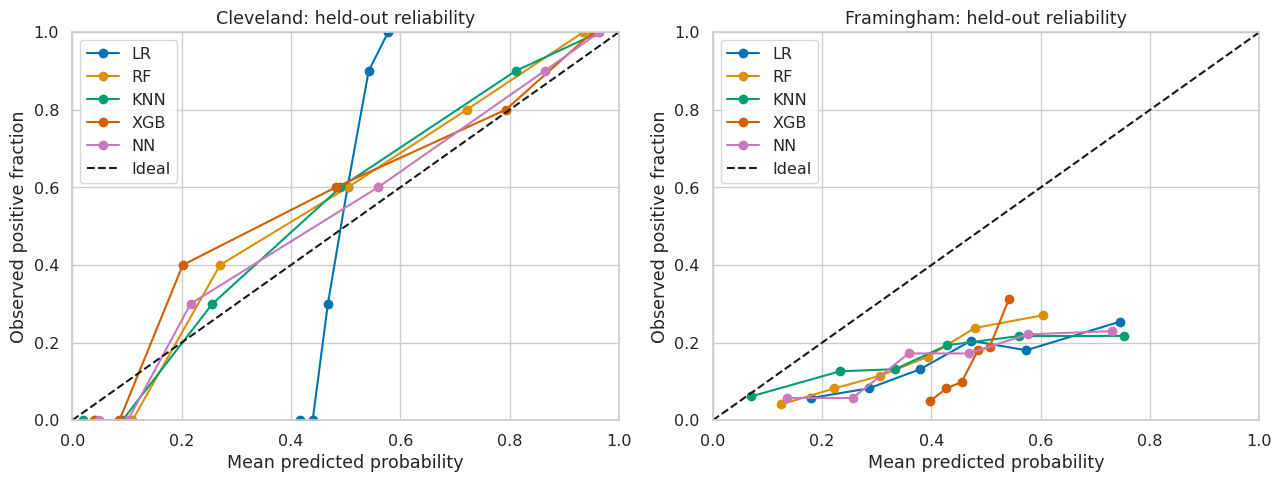

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, dataset in zip(axes, splits):
    for model in MODELS:
        observed, predicted = calibration_curve(splits[dataset][3],
            probabilities[dataset, model], n_bins=6, strategy='quantile')
        ax.plot(predicted, observed, 'o-', color=COLORS[model], label=model)
    ax.plot([0, 1], [0, 1], 'k--', label='Ideal')
    ax.set(title=f'{dataset}: held-out reliability', xlabel='Mean predicted probability',
           ylabel='Observed positive fraction', xlim=(0, 1), ylim=(0, 1))
    ax.legend()
plt.tight_layout()
plt.show()


Points below the diagonal indicate overprediction in that bin. Quantile bins contain few Cleveland patients and are noisy; these are reliability diagnostics, not fitted calibration corrections.

### Exact paper targets and differences

The next constants transcribe [Table 2 (Framingham)](https://pmc.ncbi.nlm.nih.gov/articles/PMC13298444/#epidemiologia-07-00075-t002) and [Table 3 (Cleveland)](https://pmc.ncbi.nlm.nih.gov/articles/PMC13298444/#epidemiologia-07-00075-t003). Column order is the seven metrics above. The comparison and differences are calculated from our held-out predictions, never entered manually.

In [23]:
PAPER_VALUES = {
    'Framingham': {
        'LR': [0.6803, 0.2764, 0.6847, 0.3938, 0.2698, 0.7234, 0.2138],
        'RF': [0.7391, 0.2872, 0.4865, 0.3612, 0.2222, 0.6929, 0.1750],
        'KNN': [0.6489, 0.2448, 0.6306, 0.3526, 0.2079, 0.6741, 0.2271],
        'XGB': [0.6899, 0.2456, 0.5045, 0.3304, 0.1762, 0.6882, 0.2255],
        'NN': [0.7719, 0.2812, 0.3243, 0.3013, 0.1664, 0.6625, 0.2048],
    },
    'Cleveland': {
        'LR': [0.8667, 0.8571, 0.8571, 0.8571, 0.7321, 0.9475, 0.2096],
        'RF': [0.8333, 0.8462, 0.7857, 0.8148, 0.6652, 0.9275, 0.1122],
        'KNN': [0.8333, 0.8462, 0.7857, 0.8148, 0.6652, 0.9531, 0.0942],
        'XGB': [0.8333, 0.8750, 0.7500, 0.8077, 0.6683, 0.9364, 0.1087],
        'NN': [0.8500, 0.8276, 0.8571, 0.8421, 0.6997, 0.8867, 0.1360],
    },
}
paper = pd.DataFrame([dict(Dataset=dataset, Model=model, **dict(zip(METRICS, values)))
    for dataset, models in PAPER_VALUES.items() for model, values in models.items()])
comparison = ours.melt(['Dataset', 'Model'], var_name='Metric', value_name='Ours').merge(
    paper.melt(['Dataset', 'Model'], var_name='Metric', value_name='Paper'),
    on=['Dataset', 'Model', 'Metric'], validate='one_to_one')
comparison['Difference (ours − paper)'] = comparison.Ours - comparison.Paper
for dataset in splits:
    display(Markdown(f'**{dataset}: every metric and model**'))
    display(comparison.query('Dataset == @dataset').set_index(['Model', 'Metric']).drop(columns='Dataset').round(4))


**Cleveland: every metric and model**

,,Ours,Paper,Difference (ours − paper)
Model,Metric,,,
LR,Accuracy,0.9000,0.8667,0.0333
RF,Accuracy,0.8500,0.8333,0.0167
KNN,Accuracy,0.8333,0.8333,0.0000
XGB,Accuracy,0.8333,0.8333,0.0000
NN,Accuracy,0.8333,0.8500,-0.0167
LR,Precision,0.9231,0.8571,0.0660
RF,Precision,0.8519,0.8462,0.0057
KNN,Precision,0.8750,0.8462,0.0288
XGB,Precision,0.8750,0.8750,0.0000


**Framingham: every metric and model**

,,Ours,Paper,Difference (ours − paper)
Model,Metric,,,
LR,Accuracy,0.6393,0.6803,-0.0410
RF,Accuracy,0.7568,0.7391,0.0177
KNN,Accuracy,0.6667,0.6489,0.0178
XGB,Accuracy,0.7117,0.6899,0.0218
NN,Accuracy,0.6325,0.7719,-0.1394
LR,Precision,0.2258,0.2764,-0.0506
RF,Precision,0.2781,0.2872,-0.0091
KNN,Precision,0.2170,0.2448,-0.0278
XGB,Precision,0.2642,0.2456,0.0186


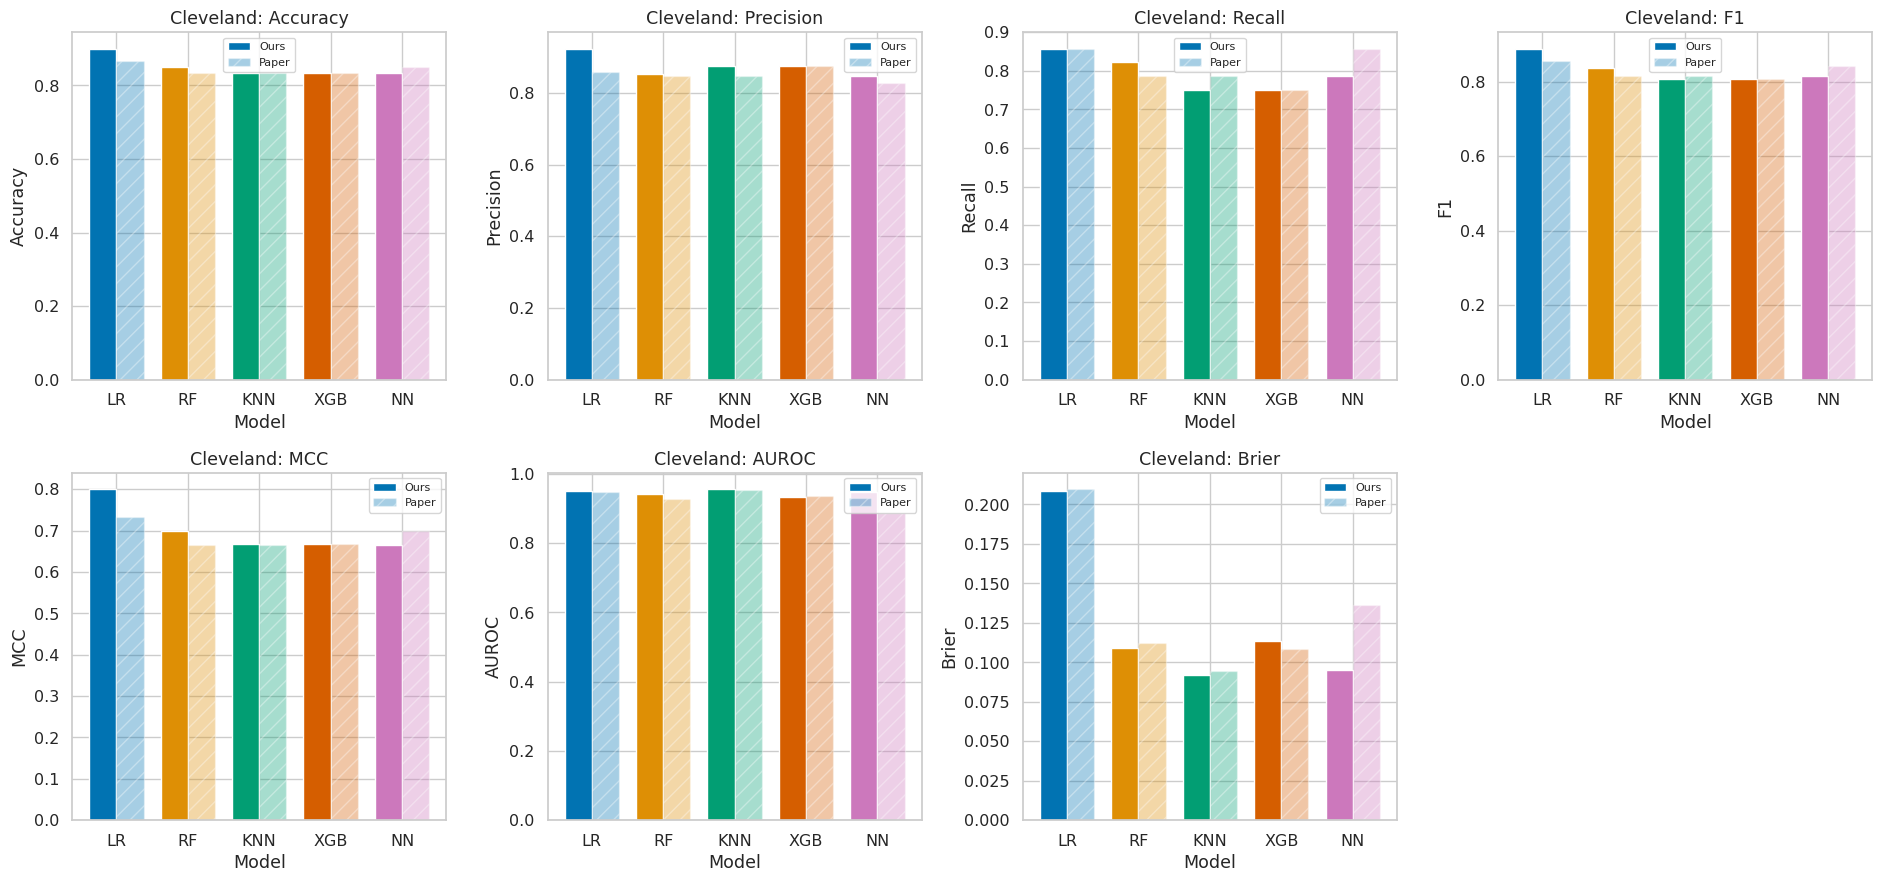

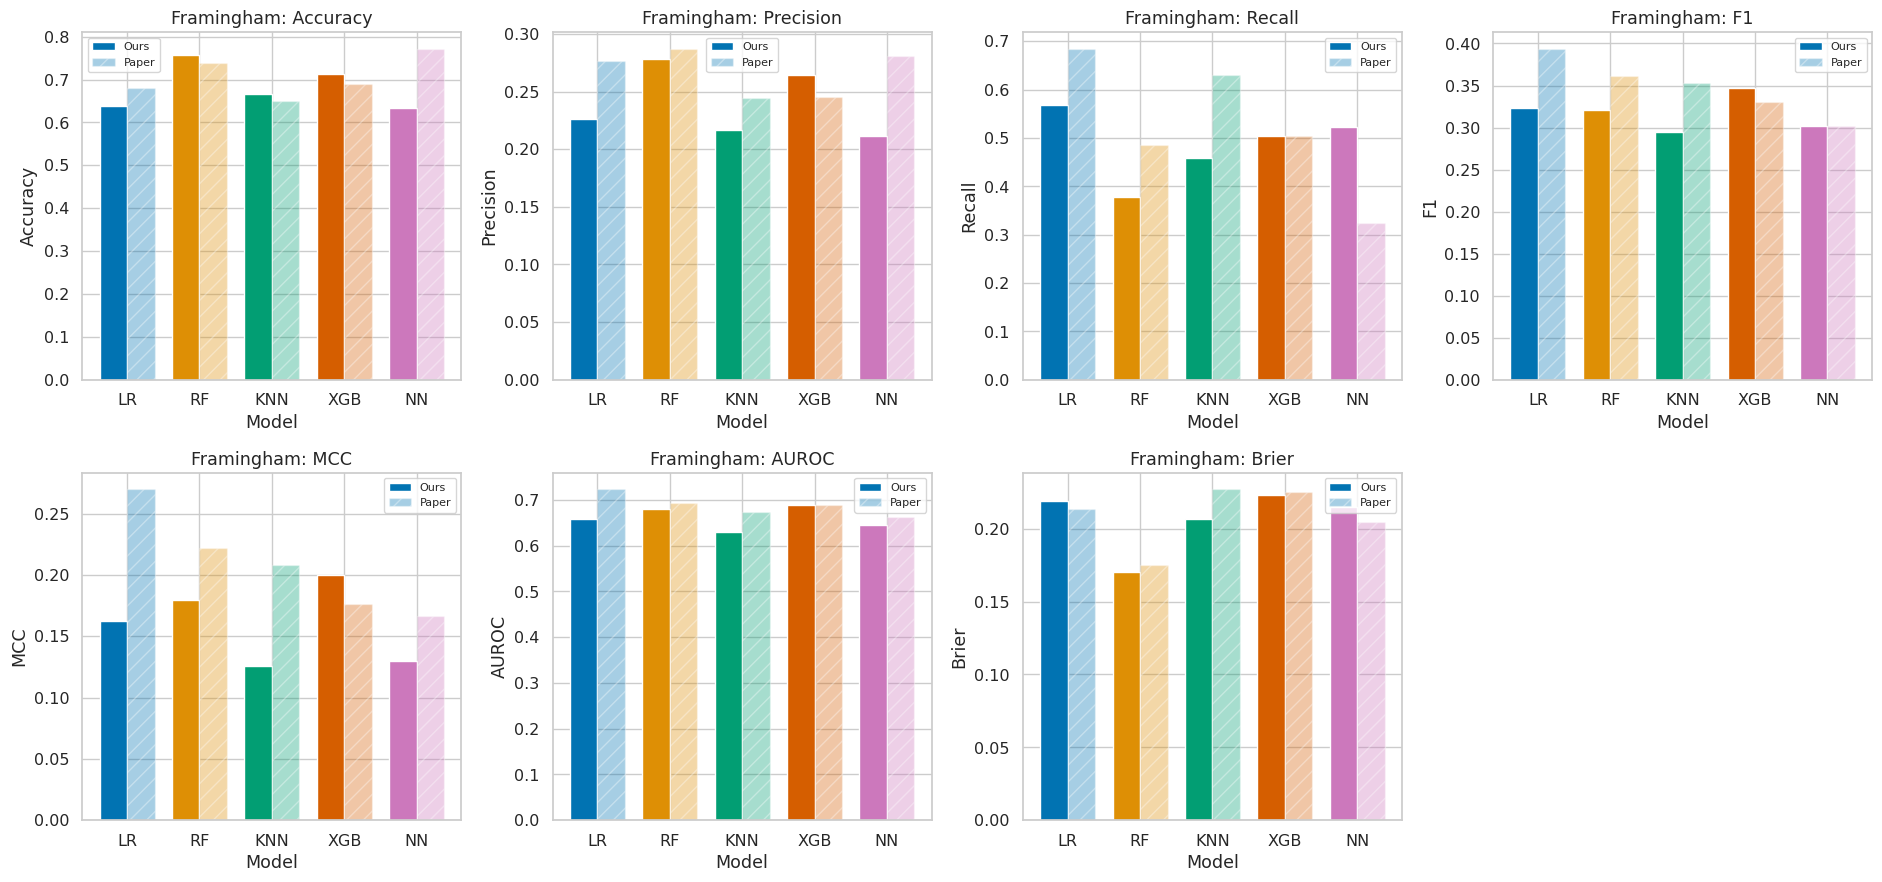

In [24]:
for dataset in splits:
    fig, axes = plt.subplots(2, 4, figsize=(19, 9))
    for ax, metric in zip(axes.flat, METRICS):
        data = comparison.query('Dataset == @dataset and Metric == @metric').set_index('Model').loc[MODELS]
        positions = np.arange(len(MODELS))
        ax.bar(positions - 0.19, data.Ours, width=0.38,
               color=[COLORS[m] for m in MODELS], label='Ours')
        ax.bar(positions + 0.19, data.Paper, width=0.38,
               color=[COLORS[m] for m in MODELS], alpha=0.35, hatch='//', label='Paper')
        ax.set_xticks(positions, MODELS)
        ax.set(title=f'{dataset}: {metric}', ylabel=metric, xlabel='Model')
        ax.legend(fontsize=8)
    axes.flat[-1].axis('off')
    plt.tight_layout()
    plt.show()


Solid bars are our fixed-setting results; translucent hatched bars are the paper's reported values, using a consistent colour for each model. Differences are expected from unspecified seeds, sampler ratios, encodings, software, and NN design; matching one number would not establish exact implementation equivalence.

## 8. XGBoost SHAP — paper §2.4, Figs 5–6

The paper explains XGBoost, so we apply TreeExplainer to both fitted XGBoost models. Explain the untouched test feature vectors after the **training-fitted** scaler, with tree-path-dependent background and raw log-odds output (our explicit explainer assumptions). Features displayed in the explanations are in original units. The attribution sample is the complete held-out set, not a post-hoc favourable subset.

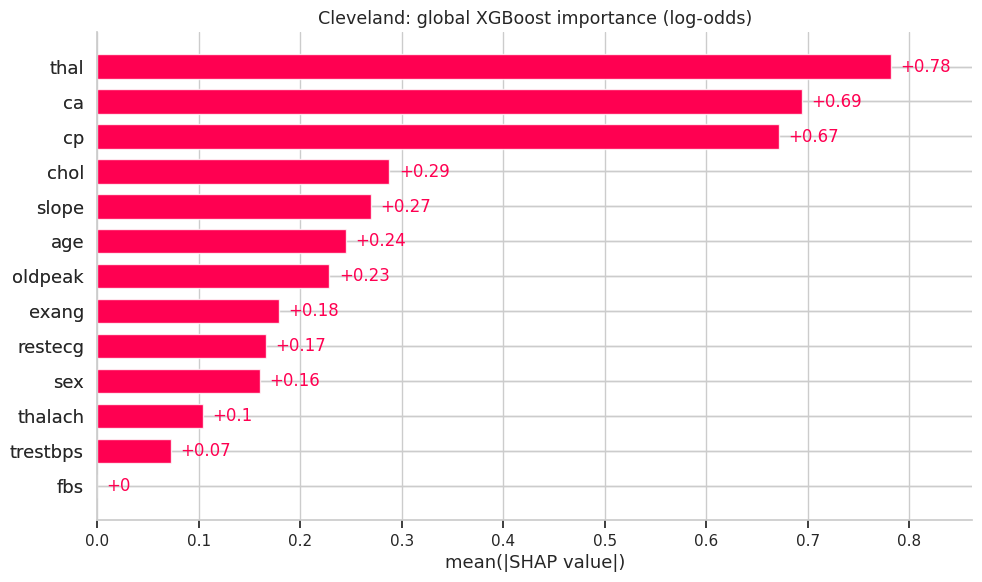

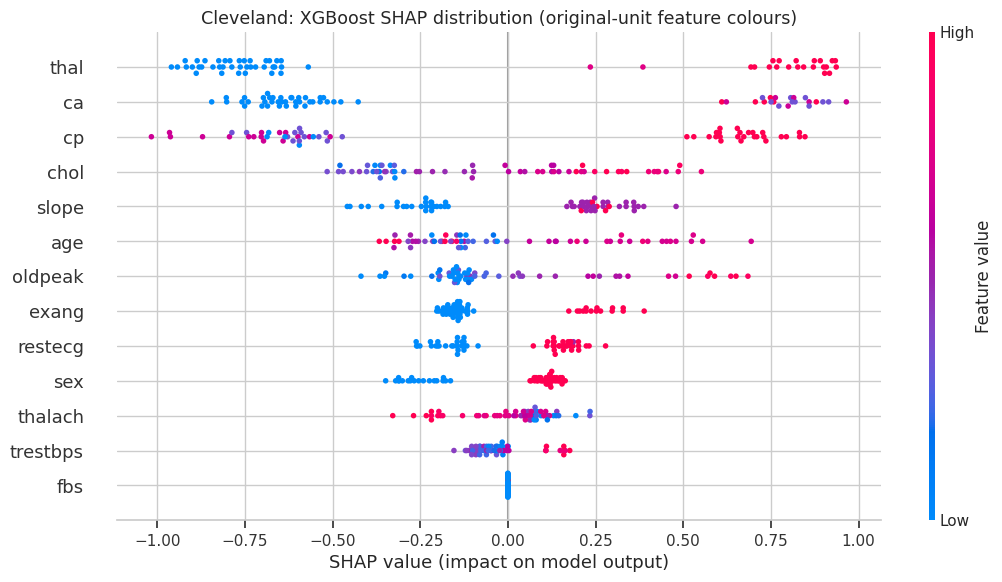

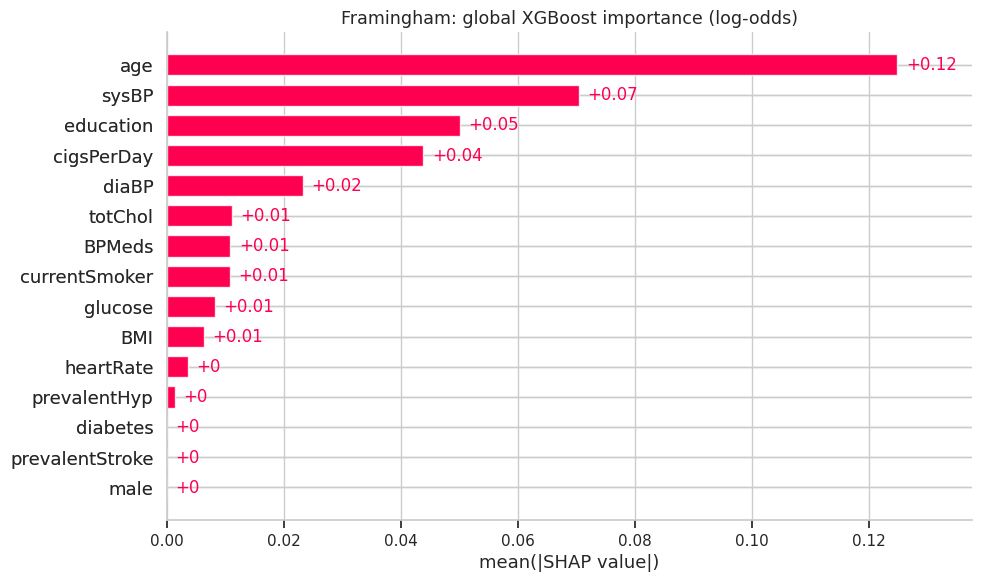

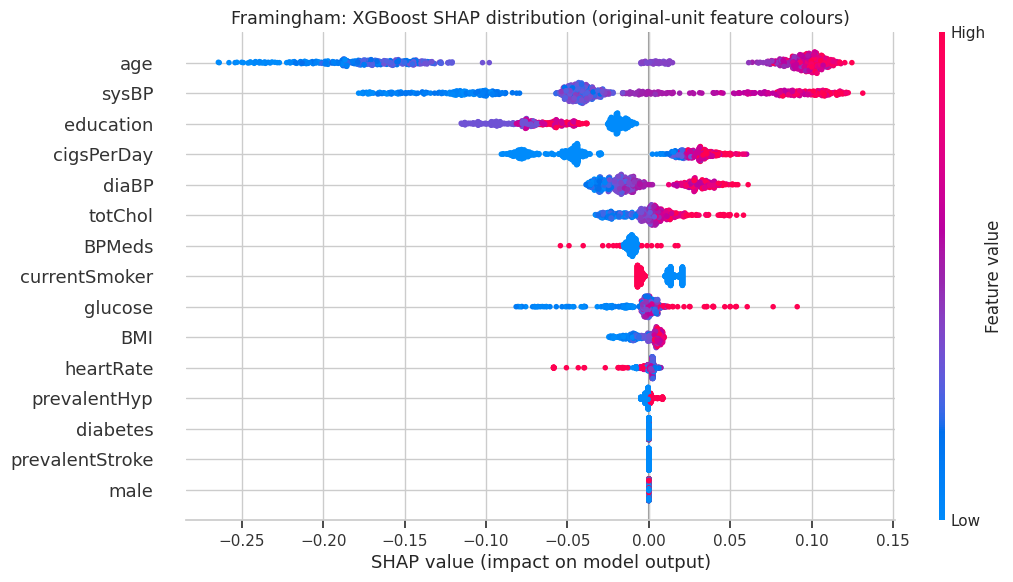

In [25]:
explanations, shap_rankings = {}, {}
for dataset, (_, X_test, _, _) in splits.items():
    pipeline = fitted[dataset, 'XGB']
    transformed = pipeline.named_steps['scale'].transform(X_test)
    explainer = shap.TreeExplainer(pipeline.named_steps['model'],
        feature_perturbation='tree_path_dependent', model_output='raw')
    explanation = explainer(transformed)
    margin = pipeline.named_steps['model'].predict(transformed, output_margin=True)
    np.testing.assert_allclose(explanation.values.sum(axis=1) + explanation.base_values,
                               margin, atol=1e-5)
    explanation.data = X_test.to_numpy()
    explanation.feature_names = list(X_test.columns)
    explanations[dataset] = explanation
    shap_rankings[dataset] = pd.Series(np.abs(explanation.values).mean(axis=0),
        index=X_test.columns, name='Mean |SHAP|').sort_values(ascending=False)
    shap.plots.bar(explanation, max_display=len(X_test.columns), show=False)
    plt.gcf().set_size_inches(10, 6)
    plt.title(f'{dataset}: global XGBoost importance (log-odds)')
    plt.tight_layout()
    plt.show()
    np.random.seed(SEED)
    shap.plots.beeswarm(explanation, max_display=len(X_test.columns), show=False)
    plt.gcf().set_size_inches(11, 6)
    plt.title(f'{dataset}: XGBoost SHAP distribution (original-unit feature colours)')
    plt.tight_layout()
    plt.show()


The bars average attribution magnitude, while beeswarms show both direction and between-patient variation. A positive SHAP value increases this model's log-odds relative to its background; it does not demonstrate that intervening on the feature changes disease risk.

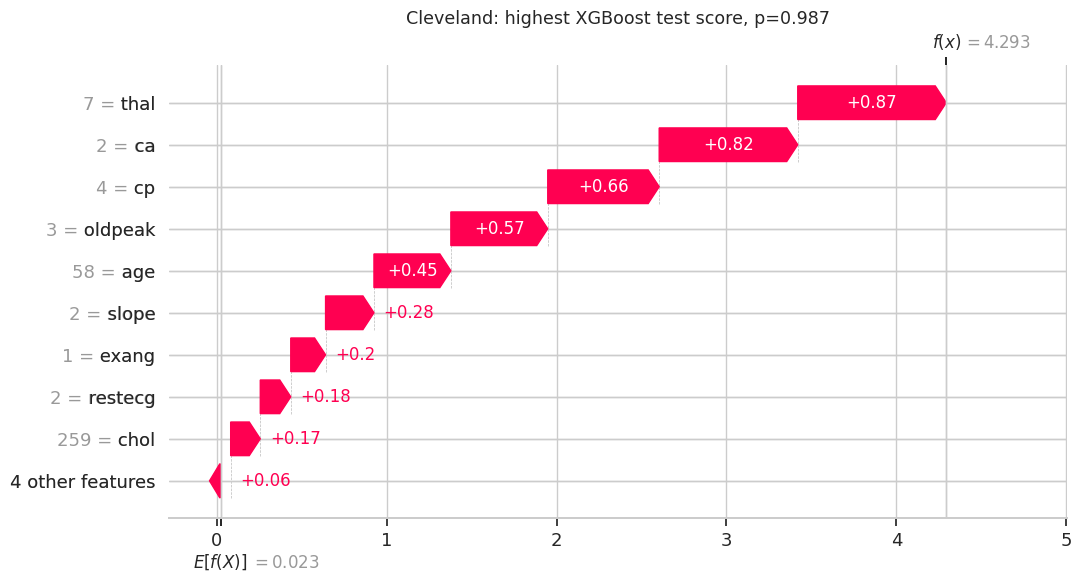

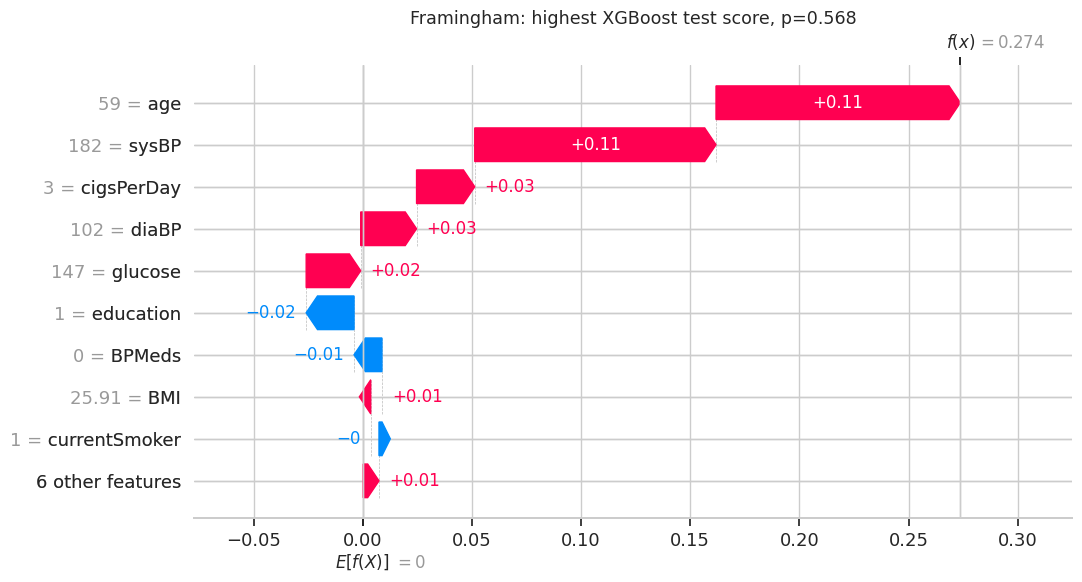

,Dataset,Paper features,Our top features,Overlap
0,Cleveland,"ca, cp, thal, age","thal, ca, cp, chol",3
1,Framingham,"sysBP, currentSmoker, prevalentHyp","age, sysBP, education",1


In [26]:
PAPER_TOP = {'Framingham': ['sysBP', 'currentSmoker', 'prevalentHyp'],
             'Cleveland': ['ca', 'cp', 'thal', 'age']}
shap_rows = []
for dataset in splits:
    high_risk = int(np.argmax(probabilities[dataset, 'XGB']))
    shap.plots.waterfall(explanations[dataset][high_risk], max_display=10, show=False)
    plt.gcf().set_size_inches(11, 6)
    plt.title(f'{dataset}: highest XGBoost test score, p={probabilities[dataset, "XGB"][high_risk]:.3f}')
    plt.tight_layout()
    plt.show()
    top = shap_rankings[dataset].head(len(PAPER_TOP[dataset])).index.tolist()
    overlap = set(top) & set(PAPER_TOP[dataset])
    shap_rows.append([dataset, ', '.join(PAPER_TOP[dataset]), ', '.join(top), len(overlap)])
shap_comparison = pd.DataFrame(shap_rows, columns=['Dataset', 'Paper features', 'Our top features', 'Overlap'])
display(shap_comparison)


Each waterfall deliberately selects the **highest predicted score**, not a representative patient; it explains that one prediction. For a strict comparison we map the paper's “smoking” to `currentSmoker` and “hypertension” to `prevalentHyp`; `cigsPerDay` is related but is not counted as the same feature. The table measures overlap at the paper's stated top-k length, without claiming agreement in exact order.

## 9. Beyond the paper: split stability and balancing ablation

Repeat the entire **fixed-parameter** fit over `N_SPLITS=50` stratified 80/20 splits (split and estimator seeds 0…49). Both datasets, all five models, and both balancing conditions use matched splits. Each NN still trains for 100 epochs. The full **500-split** analysis is available in [PR #2](https://github.com/mc5eamus/replicate-raman-2026-heart-ml/pull/2); this notebook's default is a CPU-friendly exploratory estimate, targeting <15 minutes, not that full experiment.

We report empirical 2.5–97.5 percentiles across splits. They describe split sensitivity, **not** population confidence intervals or independent replications, because test sets overlap. Following the original issue's operational definition, a paper value is “reproduced” below if it lies in that interval; this is weaker than exact numerical replication. Ranking support requires >50% of split wins, with ties sharing one win.

In [27]:
stability_start = time.perf_counter()
stability_rows = []
for dataset, frame in clean.items():
    X, y = frame.drop(columns='outcome'), frame.outcome
    for split_seed in range(N_SPLITS):
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, stratify=y, random_state=split_seed)
        assert set(X_train.index).isdisjoint(X_test.index)
        for balanced in [True, False]:
            for model in MODELS:
                pipeline = make_pipeline(dataset, model, seed=split_seed, balanced=balanced)
                pipeline.fit(X_train, y_train)
                probability = pipeline.predict_proba(X_test)[:, 1]
                stability_rows.append(dict(Dataset=dataset, Model=model, Split=split_seed,
                    Balanced=balanced, **evaluate(y_test, probability)))
    print(f'{dataset}: completed {N_SPLITS} paired balanced/unbalanced splits')
stability = pd.DataFrame(stability_rows)
assert len(stability) == len(clean) * N_SPLITS * 2 * len(MODELS)
assert np.isfinite(stability[METRICS].to_numpy()).all()
assert not stability.duplicated(['Dataset', 'Model', 'Split', 'Balanced']).any()
print(f'Stability elapsed: {(time.perf_counter() - stability_start) / 60:.2f} minutes')


Cleveland: completed 50 paired balanced/unbalanced splits


Framingham: completed 50 paired balanced/unbalanced splits
Stability elapsed: 1.50 minutes


,Dataset,Model,Balanced,Metric,Mean,SD,Lower,Upper
7,Cleveland,KNN,True,AUROC,0.9061,0.0361,0.8425,0.9588
8,Cleveland,KNN,True,Accuracy,0.8337,0.0459,0.7538,0.9129
9,Cleveland,KNN,True,Brier,0.1215,0.0248,0.0818,0.1636
21,Cleveland,LR,True,AUROC,0.9032,0.0396,0.8228,0.9593
22,Cleveland,LR,True,Accuracy,0.8407,0.0442,0.7667,0.9129
23,Cleveland,LR,True,Brier,0.2131,0.0040,0.2071,0.2217
35,Cleveland,NN,True,AUROC,0.9017,0.0404,0.8220,0.9591
36,Cleveland,NN,True,Accuracy,0.8353,0.0446,0.7538,0.9129
37,Cleveland,NN,True,Brier,0.1237,0.0269,0.0808,0.1695
49,Cleveland,RF,True,AUROC,0.9038,0.0367,0.8249,0.9543


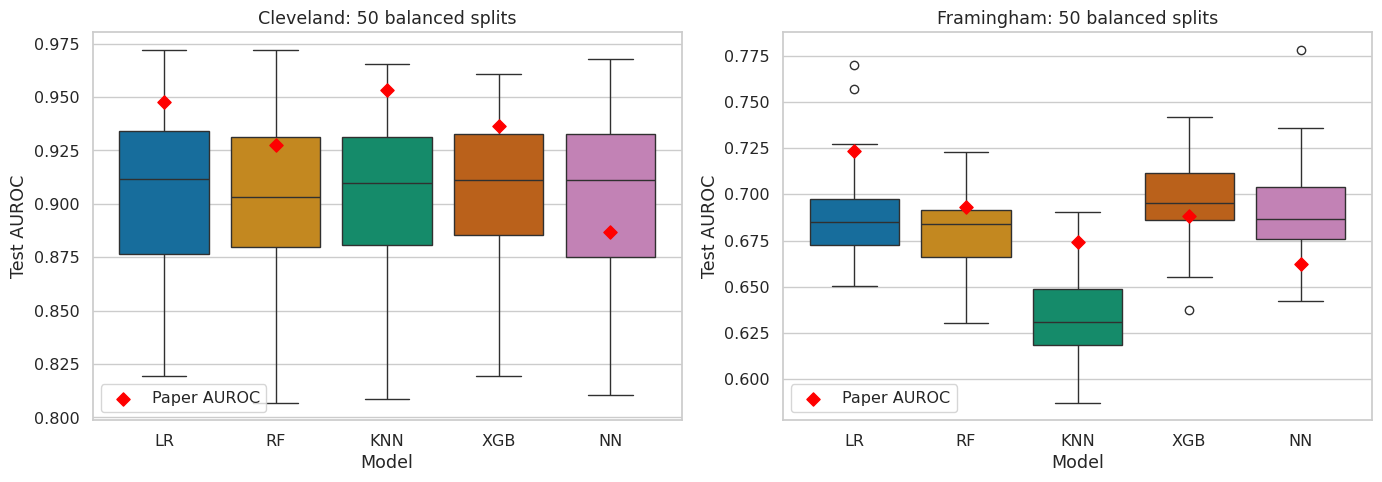

In [28]:
stability_long = stability.melt(['Dataset', 'Model', 'Split', 'Balanced'],
    value_vars=METRICS, var_name='Metric', value_name='Value')
summary = stability_long.groupby(['Dataset', 'Model', 'Balanced', 'Metric']).Value.agg(
    Mean='mean', SD='std', Lower=lambda x: x.quantile(0.025), Upper=lambda x: x.quantile(0.975)).reset_index()
display(summary.query('Balanced and Metric in ["AUROC", "Accuracy", "Brier"]').round(4))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, dataset in zip(axes, splits):
    subset = stability.query('Dataset == @dataset and Balanced')
    sns.boxplot(data=subset, x='Model', y='AUROC', order=MODELS, hue='Model',
                palette=COLORS, dodge=False, legend=False, ax=ax)
    targets = paper.query('Dataset == @dataset').set_index('Model').loc[MODELS, 'AUROC']
    ax.scatter(range(len(MODELS)), targets, marker='D', color='red', s=45, zorder=5, label='Paper AUROC')
    ax.set(title=f'{dataset}: {N_SPLITS} balanced splits', xlabel='Model', ylabel='Test AUROC')
    ax.legend()
plt.tight_layout()
plt.show()


The red diamonds locate the paper's single-split AUROC within our split distributions. A target inside a broad distribution is compatible with split variation, not proof that the original training code has been recovered.

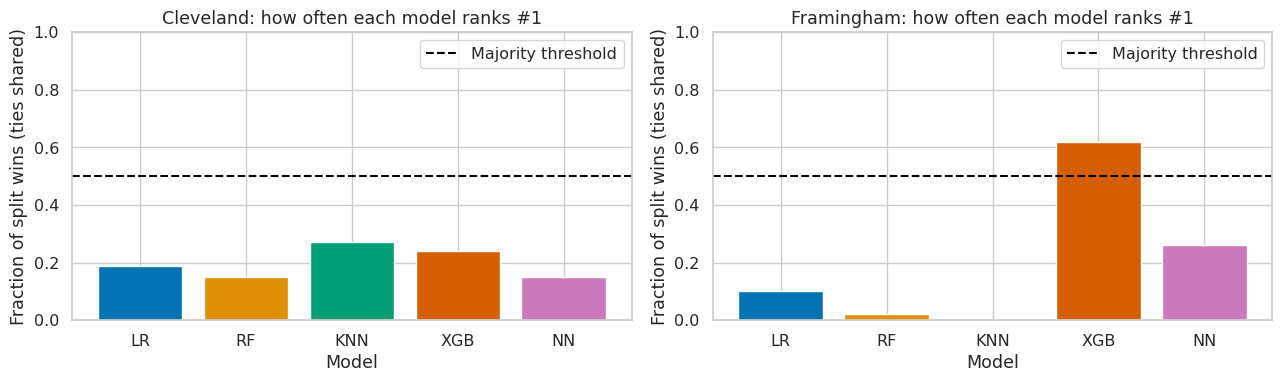

,Dataset,Model,Balanced,Wins,Win fraction
0,Cleveland,KNN,False,12.0,0.24
1,Cleveland,KNN,True,13.5,0.27
2,Cleveland,LR,False,10.5,0.21
3,Cleveland,LR,True,9.5,0.19
4,Cleveland,NN,False,8.5,0.17
5,Cleveland,NN,True,7.5,0.15
6,Cleveland,RF,False,9.0,0.18
7,Cleveland,RF,True,7.5,0.15
8,Cleveland,XGB,False,10.0,0.20
9,Cleveland,XGB,True,12.0,0.24


In [29]:
def fractional_wins(frame):
    result = frame.copy()
    best = result.groupby(['Dataset', 'Split', 'Balanced']).AUROC.transform('max')
    result['Winner'] = np.isclose(result.AUROC, best, rtol=0, atol=1e-12).astype(float)
    tied = result.groupby(['Dataset', 'Split', 'Balanced']).Winner.transform('sum')
    result['Win share'] = result.Winner / tied
    return result

ranked = fractional_wins(stability)
wins = ranked.groupby(['Dataset', 'Model', 'Balanced'])['Win share'].sum().rename('Wins').reset_index()
wins['Win fraction'] = wins.Wins / N_SPLITS
np.testing.assert_allclose(wins.groupby(['Dataset', 'Balanced']).Wins.sum(), N_SPLITS)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, dataset in zip(axes, splits):
    values = wins.query('Dataset == @dataset and Balanced').set_index('Model').loc[MODELS]
    ax.bar(MODELS, values['Win fraction'], color=[COLORS[m] for m in MODELS])
    ax.axhline(0.5, color='black', linestyle='--', label='Majority threshold')
    ax.set(title=f'{dataset}: how often each model ranks #1', xlabel='Model',
           ylabel='Fraction of split wins (ties shared)', ylim=(0, 1))
    ax.legend()
plt.tight_layout()
plt.show()
display(wins.round(3))


A model can have the largest mean AUROC without winning most splits. Lack of a majority means that this notebook does not support a stable winner; it is **not** a formal test establishing statistical equivalence.

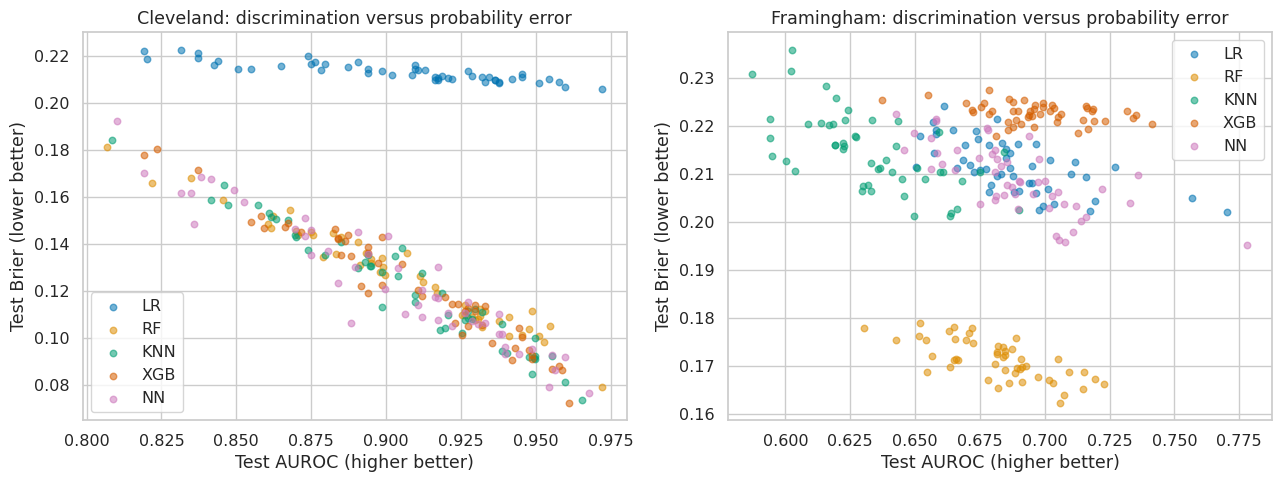

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, dataset in zip(axes, splits):
    for model in MODELS:
        subset = stability.query('Dataset == @dataset and Model == @model and Balanced')
        ax.scatter(subset.AUROC, subset.Brier, color=COLORS[model], alpha=0.55, s=22, label=model)
    ax.set(title=f'{dataset}: discrimination versus probability error',
           xlabel='Test AUROC (higher better)', ylabel='Test Brier (lower better)')
    ax.legend()
plt.tight_layout()
plt.show()


Desirable performance lies toward the lower-right. Discrimination and probability error need not move together: a strongly regularized model or changed training prior can preserve ranking while compressing or shifting probabilities.

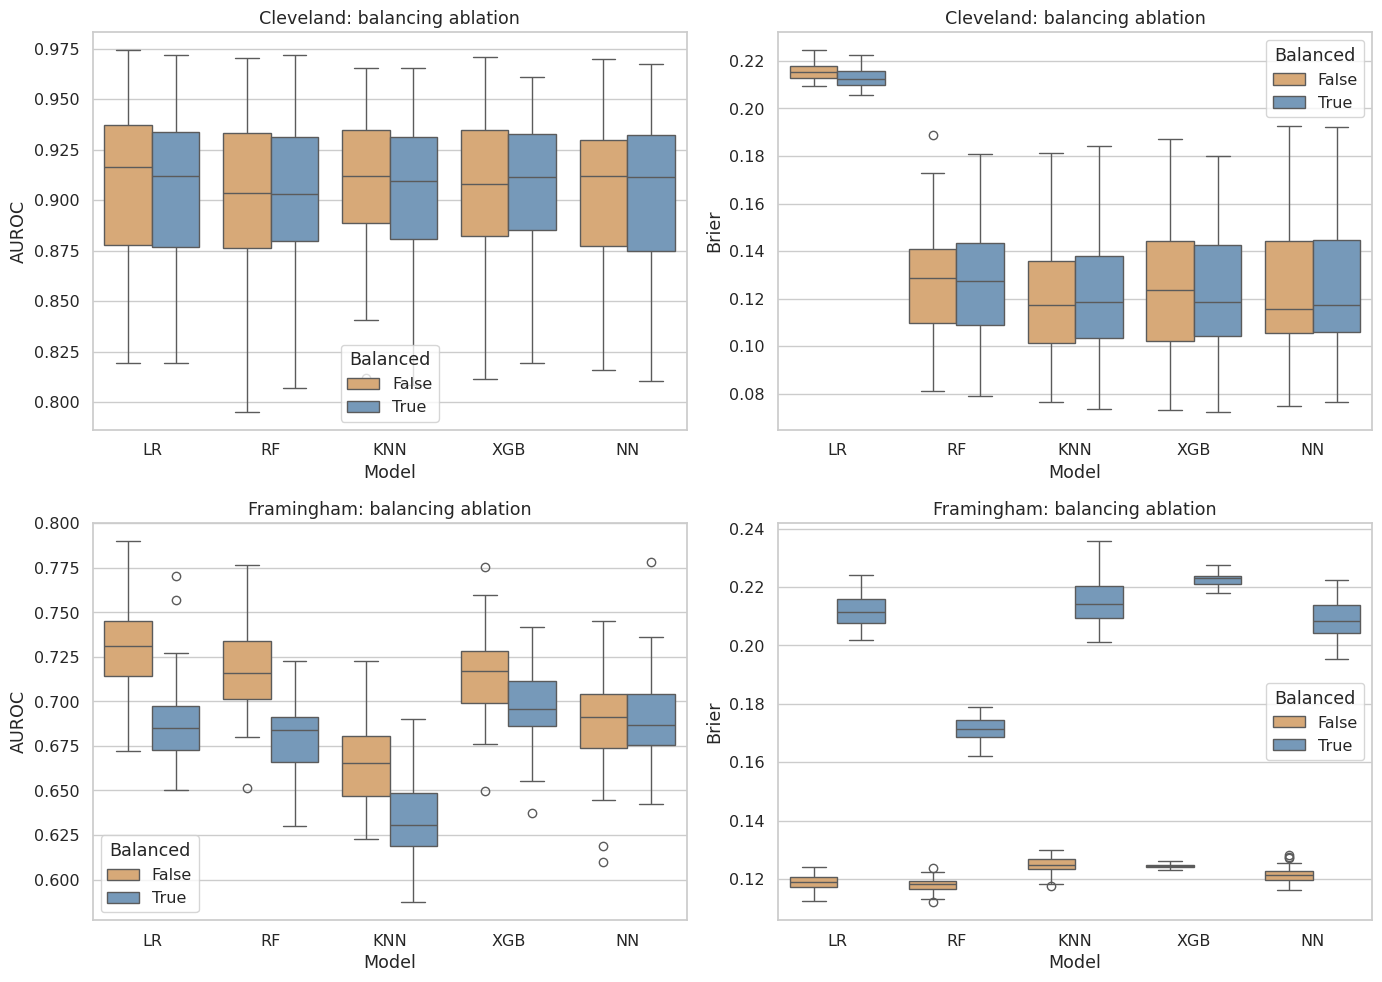

Mean ΔAUROC (balanced − off)  Mean ΔBrier (balanced − off)
Dataset    Model                                                            
Cleveland  KNN                         -0.0021                        0.0005
           LR                          -0.0009                       -0.0026
           NN                          -0.0008                        0.0010
           RF                           0.0012                       -0.0010
           XGB                          0.0006                       -0.0013
Framingham KNN                         -0.0322                        0.0897
           LR                          -0.0414                        0.0926
           NN                           0.0030                        0.0874
           RF                          -0.0350                        0.0532
           XGB                         -0.0190                        0.0983

**Framingham LR:** balancing changes mean AUROC by -0.0414 and Brier by +0.0926; positive ΔBrier means worse probability error.

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for row, dataset in enumerate(splits):
    for col, metric in enumerate(['AUROC', 'Brier']):
        ax = axes[row, col]
        subset = stability.query('Dataset == @dataset')
        sns.boxplot(data=subset, x='Model', y=metric, order=MODELS, hue='Balanced',
                    palette={True: '#6b9ac4', False: '#e7aa68'}, ax=ax)
        ax.set(title=f'{dataset}: balancing ablation', ylabel=metric, xlabel='Model')
plt.tight_layout()
plt.show()
paired = stability.pivot(index=['Dataset', 'Model', 'Split'], columns='Balanced', values=['AUROC', 'Brier'])
paired_delta = pd.DataFrame({metric: paired[metric][True] - paired[metric][False]
                            for metric in ['AUROC', 'Brier']})
display(paired_delta.groupby(['Dataset', 'Model']).mean().rename(
    columns={'AUROC': 'Mean ΔAUROC (balanced − off)', 'Brier': 'Mean ΔBrier (balanced − off)'}).round(4))
lr_delta = paired_delta.xs(('Framingham', 'LR'), level=('Dataset', 'Model')).mean()
display(Markdown(f'**Framingham LR:** balancing changes mean AUROC by {lr_delta.AUROC:+.4f} '
                 f'and Brier by {lr_delta.Brier:+.4f}; positive ΔBrier means worse probability error.'))


The ablation uses the same split seeds, estimators, scaling, and NN epochs; only SMOTE and undersampling are removed. Blue/orange denote the **balancing condition** in this plot rather than model identity. The paired differences above isolate its observed effect more clearly than comparing unrelated random splits.

## 10. Computed conclusions and limitations

The following table derives its statuses from the computed results. For numeric claims, “reproduced” means the paper target lies inside the empirical balanced-split 95% range, not exact equality. An aggregate claim is “partially” reproduced if only some components pass. For the paper's AUROC winner, support requires >50% fractional wins. SHAP claims use the strict top-k overlap defined above; no inferential or causal claim is made.

In [32]:
numeric_claims = summary.query('Balanced').merge(
    paper.melt(['Dataset', 'Model'], var_name='Metric', value_name='Paper'),
    on=['Dataset', 'Model', 'Metric'], validate='one_to_one')
numeric_claims['Inside interval'] = numeric_claims.Paper.between(numeric_claims.Lower, numeric_claims.Upper)
display(numeric_claims[['Dataset', 'Model', 'Metric', 'Paper', 'Mean', 'Lower', 'Upper', 'Inside interval']].round(4))

def reproduction_status(passed):
    passed = np.asarray(passed, dtype=bool)
    return 'reproduced' if passed.all() else ('partially' if passed.any() else 'not reproduced')

conclusion_rows = []
for dataset in splits:
    auc = numeric_claims.query('Dataset == @dataset and Metric == "AUROC"')
    conclusion_rows.append([f'{dataset}: five reported AUROCs', reproduction_status(auc['Inside interval']),
        f'{int(auc["Inside interval"].sum())}/5 targets within split intervals'])
    target = paper.query('Dataset == @dataset').set_index('Model')
    winner = target.AUROC.idxmax()
    win_fraction = wins.query('Dataset == @dataset and Model == @winner and Balanced')['Win fraction'].iloc[0]
    conclusion_rows.append([f'{dataset}: {winner} is the AUROC winner',
        reproduction_status([win_fraction > 0.5]), f'{winner} wins {win_fraction:.1%} of splits; criterion >50%'])
    overlap = shap_comparison.query('Dataset == @dataset').Overlap.iloc[0]
    k = len(PAPER_TOP[dataset])
    conclusion_rows.append([f'{dataset}: reported SHAP feature set',
        reproduction_status([feature in shap_rankings[dataset].head(k).index for feature in PAPER_TOP[dataset]]),
        f'{overlap}/{k} strict top-feature overlap'])


,Dataset,Model,Metric,Paper,Mean,Lower,Upper,Inside interval
0,Cleveland,KNN,AUROC,0.9531,0.9061,0.8425,0.9588,True
1,Cleveland,KNN,Accuracy,0.8333,0.8337,0.7538,0.9129,True
2,Cleveland,KNN,Brier,0.0942,0.1215,0.0818,0.1636,True
3,Cleveland,KNN,F1,0.8148,0.8147,0.7281,0.9063,True
4,Cleveland,KNN,MCC,0.6652,0.6687,0.5048,0.8264,True
...,...,...,...,...,...,...,...,...
65,Framingham,XGB,Brier,0.2255,0.2227,0.2186,0.2262,True
66,Framingham,XGB,F1,0.3304,0.3535,0.3150,0.4004,True
67,Framingham,XGB,MCC,0.1762,0.2106,0.1547,0.2735,True
68,Framingham,XGB,Precision,0.2456,0.2736,0.2266,0.3202,True


In [33]:
for dataset, model, metric in [('Cleveland', 'LR', 'Accuracy'), ('Cleveland', 'LR', 'MCC'),
    ('Cleveland', 'KNN', 'Brier'), ('Framingham', 'RF', 'Brier'), ('Framingham', 'NN', 'Accuracy')]:
    row = numeric_claims.query('Dataset == @dataset and Model == @model and Metric == @metric').iloc[0]
    conclusion_rows.append([f'{dataset}: {model} {metric}={row.Paper:.4f}',
        reproduction_status([row['Inside interval']]),
        f'Our mean {row.Mean:.4f}, split range [{row.Lower:.4f}, {row.Upper:.4f}]'])
conclusions = pd.DataFrame(conclusion_rows, columns=['Paper claim', 'Status', 'Computed evidence'])
display(conclusions)
assert set(conclusions.Status) <= {'reproduced', 'not reproduced', 'partially'}
assert len(comparison) == len(clean) * len(MODELS) * len(METRICS)
assert len(numeric_claims) == len(comparison)
assert all(len(frame.columns) == (14 if dataset == 'Cleveland' else 16)
           for dataset, frame in clean.items())
elapsed = (time.perf_counter() - START) / 60
print(f'End-to-end notebook runtime: {elapsed:.2f} minutes; {N_SPLITS} splits per condition.')
print('CPU budget (<15 minutes):', 'PASS' if elapsed < 15 else 'EXCEEDED on this machine')


,Paper claim,Status,Computed evidence
0,Cleveland: five reported AUROCs,reproduced,5/5 targets within split intervals
1,Cleveland: KNN is the AUROC winner,not reproduced,KNN wins 27.0% of splits; criterion >50%
2,Cleveland: reported SHAP feature set,partially,3/4 strict top-feature overlap
3,Framingham: five reported AUROCs,reproduced,5/5 targets within split intervals
4,Framingham: LR is the AUROC winner,not reproduced,LR wins 10.0% of splits; criterion >50%
5,Framingham: reported SHAP feature set,partially,1/3 strict top-feature overlap
6,Cleveland: LR Accuracy=0.8667,reproduced,"Our mean 0.8407, split range [0.7667, 0.9129]"
7,Cleveland: LR MCC=0.7321,reproduced,"Our mean 0.6835, split range [0.5329, 0.8270]"
8,Cleveland: KNN Brier=0.0942,reproduced,"Our mean 0.1215, split range [0.0818, 0.1636]"
9,Framingham: RF Brier=0.1750,reproduced,"Our mean 0.1712, split range [0.1642, 0.1780]"


End-to-end notebook runtime: 1.96 minutes; 50 splits per condition.
CPU budget (<15 minutes): PASS


### What this experiment can and cannot establish

The computed table is the conclusion: neither a fixed narrative of success nor a leaderboard chosen after inspecting the test set. It separates interval compatibility, majority ranking support, and descriptive attribution overlap. The original paper's broad threshold-metric description also needs qualification: Cleveland XGBoost has the highest reported precision, while LR leads accuracy, F1 and MCC and ties NN recall.

**Assumption ledger (where the accessible methods are silent):**

- Numeric Cleveland category codes and Framingham education are retained, not one-hot encoded. StandardScaler transforms every predictor, including binary flags. Ordinary SMOTE can interpolate invalid category codes; SMOTENC would change the requested method.
- Split seed 42, stratified 80/20 splitting, shuffled five-fold CV seed 42, AUROC search/refit criterion, compact grids listed in §6, and pinned library defaults are our choices. Stability uses seeds 0…`N_SPLITS−1`, including estimator/sampler initialization; no inner tuning is repeated there.
- Default SMOTE k=5 to 1:1 followed by 1:1 random undersampling is our ratio assumption; undersampling then removes nothing. Scaling follows resampling as described in the paper. All transforms remain training/fold-local.
- NN input–32–16–1 with ReLU, BCEWithLogitsLoss, Adam lr=0.001, no weight decay, 100 full-batch epochs, CPU, and no early stopping are assumptions. Its architecture is not a verified paper hyperparameter.
- Threshold 0.5, zero precision for no positive predictions, uncalibrated model probabilities, XGBoost histogram trees/logloss, and one CPU worker are explicit implementation choices.
- TreeExplainer uses tree-path-dependent background, raw log-odds, and all test patients. A waterfall selects the highest predicted score. Paper “smoking” is mapped strictly to `currentSmoker`, not `cigsPerDay`; SHAP feature-set agreement ignores order.
- Empirical 2.5–97.5 split percentiles and >50% fractional-win criteria are operational checks from the reproduction issue, not statistical guarantees. Fifty splits give only a rough tail estimate; the linked 500-split experiment is preferable for precision.

**Limitations:** complete-case selection bias; a small Cleveland test set; overlapping splits; historical, geographically narrow teaching cohorts; unknown original seeds, full search grids, sampler ratios, and NN specification; possible software-version differences; no external validation, temporal validation, clinical utility assessment, fairness audit, or causal identification. Framingham and Cleveland outcomes differ fundamentally. A metric-compatible result does not imply a clinically deployable model.

**Re-run:** from the repository root, `jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=900 notebooks/raman2026_reproduction.ipynb`. Execution from the notebook directory also works. A first run requires internet for the two fingerprinted downloads; subsequent runs can use the cache.